# AST for DataSEC environmental sound classification

This notebook fine-tunes a pretrained Audio Spectrogram Transformer (AST) to classify the 22 DataSEC parent classes. It covers data validation, recording-level splits, audio preprocessing, model training, validation-based checkpoint selection, test evaluation, error analysis and WAV prediction.

In a **fresh Kaggle kernel**, enable **Internet** and a **GPU accelerator**, then run all cells. Everything runs in this notebook. Each Run All starts from the original pretrained weights in a new experiment folder; the verified dataset download can be reused. The separate smoke model is discarded before full training.

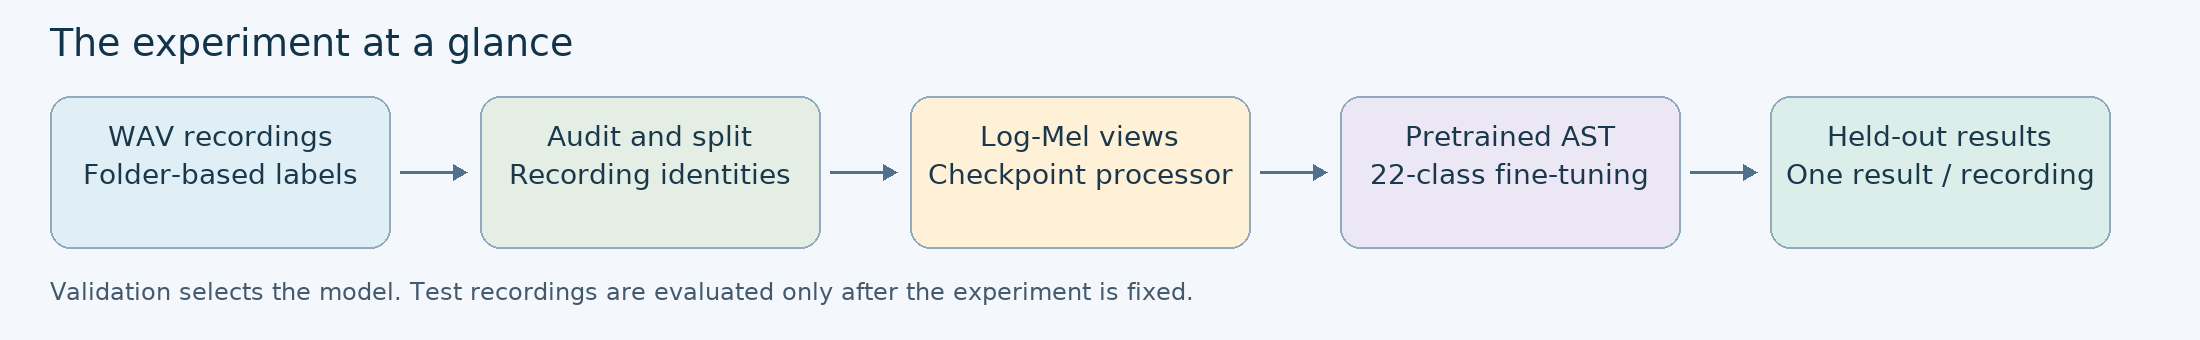

## 1. Setup and dataset download

Install dependencies before importing them. Kaggle's existing PyTorch and audio packages are retained so their CUDA builds stay matched. The download is verified against the expected archive checksum, and extraction discovers the dataset folder automatically. Interrupted downloads are retried; a completed extraction is reused.

In [1]:
# Install before importing scientific packages; do not replace Kaggle's CUDA torch build.
import subprocess, sys

subprocess.check_call(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--quiet",
        "transformers==4.57.1",
        "soundfile>=0.12,<1",
        "scipy>=1.11,<2",
        "scikit-learn>=1.3,<2",
        "pandas>=2,<3",
        "matplotlib>=3.7,<4",
        "librosa>=0.11,<0.12",
    ]
)


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


0

In [2]:
import hashlib
import os
import shutil
import stat
import time
import urllib.request
import zipfile
from pathlib import Path, PurePosixPath

# Set before any torch import or CUDA initialization.
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
os.environ.setdefault("HF_HUB_DOWNLOAD_TIMEOUT", "120")
os.environ.setdefault("HF_HUB_ETAG_TIMEOUT", "60")

download_dir = Path("/kaggle/working/datasec_download")
download_dir.mkdir(parents=True, exist_ok=True)
archive = download_dir / "DATASEC.zip"
url = "https://zenodo.org/records/17033970/files/DATASEC.zip?download=1"
expected_md5 = "29fa9b8cc84cfa69aa4e5e674e780383"


def file_md5(path):
    checksum = hashlib.md5()
    with Path(path).open("rb") as source:
        for chunk in iter(lambda: source.read(8 * 1024 * 1024), b""):
            checksum.update(chunk)
    return checksum.hexdigest()


def ensure_archive(archive, url, expected_md5):
    if archive.exists() and file_md5(archive) == expected_md5:
        print("Reusing verified archive:", archive)
        return
    temporary = archive.with_suffix(".zip.part")
    for attempt in range(1, 4):
        try:
            print(f"Downloading DATASEC (attempt {attempt}/3)...", flush=True)
            request = urllib.request.Request(
                url, headers={"User-Agent": "DataSEC-notebook/1.0"}
            )
            with urllib.request.urlopen(
                request, timeout=120
            ) as response, temporary.open("wb") as output:
                total = int(response.headers.get("Content-Length") or 0)
                received = 0
                last_report = time.monotonic()
                while chunk := response.read(8 * 1024 * 1024):
                    output.write(chunk)
                    received += len(chunk)
                    if time.monotonic() - last_report >= 15:
                        print(
                            f"  {received / 2**20:.0f} MiB received"
                            + (f" of {total / 2**20:.0f} MiB" if total else ""),
                            flush=True,
                        )
                        last_report = time.monotonic()
            if file_md5(temporary) != expected_md5:
                raise ValueError(
                    "Archive MD5 does not match the expected DATASEC release"
                )
            temporary.replace(archive)
            return
        except (OSError, ValueError) as error:
            temporary.unlink(missing_ok=True)
            if attempt == 3:
                raise RuntimeError(
                    "DATASEC download failed after three attempts. Check Kaggle Internet and free disk space."
                ) from error
            print("Download interrupted:", error, flush=True)
            time.sleep(5 * attempt)


def extract_archive(archive, destination, checksum):
    destination = Path(destination)
    marker = destination / ".datasec-extraction-complete"
    if not marker.exists() or marker.read_text().strip() != checksum:
        destination.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(archive) as bundle:
            root = destination.resolve()
            for member in bundle.infolist():
                # Validate all names before extracting any files.
                relative = PurePosixPath(member.filename.replace("\\", "/"))
                resolved = (destination / str(relative)).resolve()
                if (
                    relative.is_absolute()
                    or not resolved.is_relative_to(root)
                    or stat.S_ISLNK(member.external_attr >> 16)
                ):
                    raise ValueError(f"Unsafe archive member: {member.filename}")
            required = sum(m.file_size for m in bundle.infolist())
            if shutil.disk_usage(destination).free < required + 512 * 1024**2:
                raise OSError("Insufficient free disk space for DATASEC extraction")
            print(f"Extracting {required / 2**30:.2f} GiB...", flush=True)
            bundle.extractall(destination)
        marker.write_text(checksum)
    wavs = sorted(
        p
        for p in destination.rglob("*")
        if p.is_file()
        and p.suffix.lower() == ".wav"
        and not p.name.startswith("._")
        and "__MACOSX" not in p.parts
    )
    if not wavs:
        raise FileNotFoundError(f"No WAV recordings extracted under {destination}")
    roots = [
        p
        for p in destination.rglob("*")
        if p.is_dir()
        and p.name.upper() == "DATASEC"
        and any(w.is_relative_to(p) for w in wavs)
    ]
    data_root = (
        min(roots, key=lambda p: (len(p.parts), str(p))) if roots else destination
    )
    if any(not w.is_relative_to(data_root) for w in wavs):
        raise ValueError(
            "WAV files occur outside the selected DATASEC folder; inspect archive structure"
        )
    print("Dataset ready:", data_root, "| WAVs:", len(wavs), flush=True)
    return data_root


ensure_archive(archive, url, expected_md5)
DATA_DIR = extract_archive(archive, download_dir / "extracted", expected_md5)
DATA_ROOT = str(DATA_DIR)


  16 MiB received of 6117 MiB
  32 MiB received of 6117 MiB
  48 MiB received of 6117 MiB
  64 MiB received of 6117 MiB
  80 MiB received of 6117 MiB
  96 MiB received of 6117 MiB
  112 MiB received of 6117 MiB
  176 MiB received of 6117 MiB
  232 MiB received of 6117 MiB
  288 MiB received of 6117 MiB
  336 MiB received of 6117 MiB
  384 MiB received of 6117 MiB
  432 MiB received of 6117 MiB
  488 MiB received of 6117 MiB
  536 MiB received of 6117 MiB
  600 MiB received of 6117 MiB
  664 MiB received of 6117 MiB
  728 MiB received of 6117 MiB
  784 MiB received of 6117 MiB
  840 MiB received of 6117 MiB
  904 MiB received of 6117 MiB
  976 MiB received of 6117 MiB
  1032 MiB received of 6117 MiB
  1080 MiB received of 6117 MiB
  1136 MiB received of 6117 MiB
  1192 MiB received of 6117 MiB
  1256 MiB received of 6117 MiB
  1320 MiB received of 6117 MiB
  1368 MiB received of 6117 MiB
  1432 MiB received of 6117 MiB
  1488 MiB received of 6117 MiB
  1544 MiB received of 6117 MiB
  16

In [3]:
import os

os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
import json, math, random, time, hashlib, platform, importlib.metadata, re, gc
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import soundfile as sf
from scipy.signal import resample_poly
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import ASTConfig, ASTFeatureExtractor, ASTForAudioClassification
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, Audio, Markdown

%matplotlib inline
plt.rcParams.update(
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)


## 2. Experiment configuration and reproducibility

The default uses 16 kHz audio, a batch size of 1 and 16 gradient-accumulation steps, giving an effective batch size of 16. Training lasts up to 15 epochs with early stopping after five epochs without improved validation macro-F1. These settings reduce memory demand but do not guarantee a particular runtime or score.

Each run has a unique output directory. `EVALUATE_TEST=True` completes the fixed experiment with held-out evaluation after checkpoint selection. Set it to `False` before running if this is a development experiment. Seeds cover Python, NumPy, PyTorch and data-loader workers; exact reproducibility across hardware and package versions is not guaranteed.

In [4]:
# DATA_DIR is discovered by the verified extraction cell above.
OUTPUT = Path("/kaggle/working/ast_datasec")
RUN = OUTPUT / f"run_{datetime.now():%Y%m%d_%H%M%S_%f}"
MODE = "new"

SHARED_SPLIT = None
CLASS_MAPPING = None
GROUP_CSV = None

SEED = 42
CHECKPOINT_PATH = "MIT/ast-finetuned-audioset-10-10-0.4593"
REVISION = "f826b80d28226b62986cc218e5cec390b1096902"
FINE_TUNE_SCOPE = "full"
BATCH_SIZE = 1
GRADIENT_ACCUMULATION = 16
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 0.01
EPOCHS = 15
PATIENCE = 5
NUM_WORKERS = 0  # Reliable notebook execution; increase only after a successful run.
USE_AMP = True
EVAL_CROPS = 5
AUDIO_CACHE = None

EVALUATE_TEST = (
    True  # Fixed experiment: evaluate the validation-selected checkpoint once.
)
RUN_PREDICTION_DEMO = True

CFG = dict(
    seed=SEED,
    batch_size=BATCH_SIZE,
    accumulation=GRADIENT_ACCUMULATION,
    workers=NUM_WORKERS,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    epochs=EPOCHS,
    patience=PATIENCE,
    amp=USE_AMP,
    eval_crops=EVAL_CROPS,
    scope=FINE_TUNE_SCOPE,
    cache=AUDIO_CACHE,
    checkpoint=CHECKPOINT_PATH,
    revision=REVISION,
)
RUN_SMOKE_TEST = True
FIGURES = OUTPUT / (RUN.name + "_presentation")
FIGURES.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
display(pd.Series(CFG, name="Active setting").to_frame())
print("Mode:", MODE, "| Run:", RUN)


,Active setting
seed,42
batch_size,1
accumulation,16
workers,0
lr,0.00001
weight_decay,0.01
epochs,15
patience,5
amp,True
eval_crops,5


Mode: new | Run: /kaggle/working/ast_datasec/run_20261029_160714_238935


In [5]:
def environment():
    versions = {"python": platform.python_version()}
    for name in [
        "torch",
        "transformers",
        "torchaudio",
        "numpy",
        "scipy",
        "soundfile",
        "scikit-learn",
    ]:
        try:
            versions[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            versions[name] = "not installed (torchaudio optional)"
    versions["device"] = (
        torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
    )
    if torch.cuda.is_available():
        free, total = torch.cuda.mem_get_info()
        versions.update(gpu_free_gib=free / 2**30, gpu_total_gib=total / 2**30)
    print(versions)
    return versions


def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)


In [6]:
ENV = environment()
seed_all(CFG["seed"])
if DEVICE.type == "cpu":
    print("CPU detected; a GPU is recommended for full training.")
torch_version = tuple(int(v) for v in torch.__version__.split("+")[0].split(".")[:2])
require_torch = torch_version >= (2, 3)
if not require_torch:
    raise RuntimeError(
        "This notebook needs torch >= 2.3. Select an up-to-date Kaggle GPU image."
    )
if DEVICE.type == "cuda":
    torch.set_float32_matmul_precision("high")


{'python': '3.13.15', 'torch': '2.11.0+cu128', 'transformers': '4.57.1', 'torchaudio': '2.11.0+cu128', 'numpy': '2.1.3', 'scipy': '1.16.3', 'soundfile': '0.14.0', 'scikit-learn': '1.6.1', 'device': 'Tesla T4', 'gpu_free_gib': 14.45977783203125, 'gpu_total_gib': 14.56219482421875}


## 3. Parent labels and subclass mapping

Labels come from recognized class folders rather than filename prefixes. The resolver maps documented subclasses to 22 parent classes and stops on unknown or conflicting folders. The displayed mapping defines the class order used by the model, reports and confusion matrices.

In [7]:
PARENTS = [
    "Bells",
    "Birds",
    "Cat fights and moans",
    "Chicken coop",
    "Cicadas and crickets",
    "Crows seagulls and magpies",
    "Dog barkings and howlings",
    "Glass breaking",
    "Horn",
    "Jet aircrafts",
    "Lawn mower brush cutter and olive shaker",
    "Music",
    "Propeller aircrafts",
    "Sirens and alarms",
    "Thunder fireworks and gunshot",
    "Train",
    "Vacuum cleaner fan and hairdryer",
    "Vehicle idling",
    "Vehicle pass-by",
    "Voices",
    "Wind turbine",
    "Workshop",
]

SUBCLASSES = {
    "Cicadas and crickets": ["Cicadas", "Crickets"],
    "Crows seagulls and magpies": ["Crows", "Seagulls", "Magpies"],
    "Lawn mower brush cutter and olive shaker": [
        "Lawn mower",
        "Brush cutter",
        "Olive shaker",
    ],
    "Propeller aircrafts": ["Airplanes", "Helicopters", "Propeller airplanes"],
    "Sirens and alarms": ["Sirens", "Alarms"],
    "Thunder fireworks and gunshot": ["Thunder", "Fireworks", "Gunshot", "Gunshots"],
    "Vacuum cleaner fan and hairdryer": ["Vacuum cleaner", "Fan", "Hairdryer"],
    "Vehicle idling": [
        "Car-truck idling",
        "Car idling",
        "Truck idling",
        "Motorbike idling",
    ],
    "Vehicle pass-by": ["Car pass-by", "Motorbike pass-by", "Truck pass-by"],
    "Workshop": ["Air compressor", "Drill", "Grinder", "Jackhammer", "Saw"],
}


def norm(s):
    words = re.findall("[a-z]+", s.lower())
    return "".join((w[:-1] if w.endswith("s") else w for w in words if w != "and"))


aliases = {norm(p): p for p in PARENTS}

for parent, children in SUBCLASSES.items():
    aliases.update({norm(c): parent for c in children})


def require(condition, message):
    if not condition:
        raise ValueError(message)


In [8]:
display(
    pd.DataFrame(
        {
            "parent_class": PARENTS,
            "recognized_subclasses": [
                ", ".join(SUBCLASSES.get(p, [])) or "(parent folder)" for p in PARENTS
            ],
        }
    )
)


,parent_class,recognized_subclasses
0,Bells,(parent folder)
1,Birds,(parent folder)
2,Cat fights and moans,(parent folder)
3,Chicken coop,(parent folder)
4,Cicadas and crickets,"Cicadas, Crickets"
5,Crows seagulls and magpies,"Crows, Seagulls, Magpies"
6,Dog barkings and howlings,(parent folder)
7,Glass breaking,(parent folder)
8,Horn,(parent folder)
9,Jet aircrafts,(parent folder)


## 4. Audio integrity and recording-level splits

Every recording is decoded to check duration, sample rate, channel count, nonfinite samples, silence and exact decoded-audio duplicates. Invalid recordings are logged; identical audio with conflicting labels stops execution. Same-label duplicates are reduced to one recording before a new split is created.

The default stratified split is 70% training, 15% validation and 15% test, with all 22 classes required in each partition. `SHARED_SPLIT` and `CLASS_MAPPING` can explicitly reuse an exported team split and class IDs. A shared seed alone does not establish identical partitions across models.

Optional `GROUP_CSV` metadata keeps recordings from the same source together using 20 stratified group folds, assigned 14/3/3 to training/validation/test. Group proportions are approximate. Exact hashes cannot detect near-duplicates or establish source independence without metadata.

In [9]:
def prepare(root, output, shared=None, mapping_file=None, groups_file=None, seed=42):
    root, output = (Path(root).resolve(), Path(output))
    require(
        root.is_dir(),
        f"Dataset directory inaccessible: {root}. Attach extracted DATASEC; no download is performed.",
    )
    output.mkdir(parents=True, exist_ok=True)
    files = sorted(
        (
            p
            for p in root.rglob("*")
            if p.suffix.lower() == ".wav"
            and (not p.name.startswith("._"))
            and "__MACOSX" not in p.parts
        )
    )
    require(files, f"No WAV recordings under {root}")
    rows = []
    for p in files:
        rel = p.relative_to(root).as_posix()
        labels = {
            aliases[norm(s)]
            for s in p.relative_to(root).parts[:-1]
            if norm(s) in aliases
        }
        require(len(labels) == 1, f"Unknown/conflicting class folders: {rel}")
        row = dict(relative_path=rel, label=labels.pop(), error="")
        try:
            x, sr = sf.read(p, dtype="float32", always_2d=True)
            require(len(x) > 0 and np.isfinite(x).all(), "Empty/nonfinite audio")
            require(float(np.abs(x).max()) >= 1e-08, "Silent audio")
            h = hashlib.sha256(str((sr, x.shape)).encode())
            h.update(x.tobytes())
            row.update(
                audio_hash=h.hexdigest(),
                duration=len(x) / sr,
                sample_rate=sr,
                channels=x.shape[1],
            )
        except Exception as e:
            row["error"] = str(e)
        rows.append(row)
    inventory = pd.DataFrame(rows)
    inventory.to_csv(output / "audio_inventory.csv", index=False)
    invalid = inventory[inventory.error != ""]
    invalid.to_csv(output / "invalid_audio.csv", index=False)
    df = inventory[inventory.error == ""].copy()
    require(len(df) > 0, "No valid audio")
    require(
        df.groupby("audio_hash").label.nunique().max() == 1,
        "Identical audio has conflicting labels",
    )
    duplicates = df[df.duplicated("audio_hash", keep="first")]
    duplicates.to_csv(output / "duplicate_audio.csv", index=False)
    if shared:
        m = pd.read_csv(shared, dtype={"group_id": str}, float_precision="round_trip")
        m = m.rename(
            columns={
                "path": "relative_path",
                "label_id": "target",
                "class_id": "target",
            }
        )
        require(
            {"relative_path", "label", "split"} <= set(m),
            "Manifest requires relative_path,label,split",
        )
        require(not m.relative_path.duplicated().any(), "Duplicate manifest paths")
        require(
            set(m.relative_path) <= set(df.relative_path),
            "Manifest includes missing/invalid files; inspect inventory. Root must match manifest paths.",
        )
        omitted = df[~df.relative_path.isin(m.relative_path)]
        omitted.to_csv(output / "unassigned_recordings.csv", index=False)
        require(
            set(omitted.audio_hash)
            <= set(df[df.relative_path.isin(m.relative_path)].audio_hash),
            "Manifest omits unique valid recordings: release/subset mismatch. Resolve with team.",
        )
        check = m.merge(
            df, on="relative_path", suffixes=("_saved", ""), validate="one_to_one"
        )
        require(
            (check.label_saved == check.label).all(),
            "Manifest labels conflict with folder labels",
        )
        if "audio_hash_saved" in check:
            require(
                (check.audio_hash_saved == check.audio_hash).all(),
                "Audio changed since manifest was exported",
            )
        df = check
        if mapping_file:
            mapping = json.loads(Path(mapping_file).read_text())
        else:
            require(
                "target" in df,
                "Shared mapping missing: provide class_mapping.json or manifest target IDs",
            )
            require(
                df.groupby("label").target.nunique().max() == 1,
                "Inconsistent target IDs",
            )
            mapping = dict(zip(df.label, df.target.astype(int)))
        if "target" in df:
            require(
                (df.target == df.label.map(mapping)).all(),
                "Shared class IDs disagree with mapping",
            )
        origin = str(Path(shared).resolve())
    else:
        df = df.drop_duplicates("audio_hash").reset_index(drop=True)
        mapping = {label: i for i, label in enumerate(sorted(PARENTS))}
        origin = "NEW candidate split; not established as identical to teammate splits"
    require(
        set(mapping) == set(PARENTS) and set(mapping.values()) == set(range(22)),
        "Mapping must bijectively map 22 parent labels to IDs 0..21",
    )
    df["target"] = df.label.map(mapping)
    if groups_file:
        g = pd.read_csv(groups_file, dtype=str)
        require(
            {"relative_path", "group_id"} <= set(g)
            and (not g.relative_path.duplicated().any()),
            "Invalid group metadata",
        )
        values = df.relative_path.map(g.set_index("relative_path").group_id)
        require(
            values.notna().all() and values.str.strip().ne("").all(),
            "Missing source groups",
        )
        if "group_id" in df:
            require(
                (df.group_id.astype(str) == values).all(),
                "Conflicting supplied source groups",
            )
        df["group_id"] = values
    if "group_id" not in df:
        df["group_id"] = df.audio_hash
    require(df.group_id.notna().all(), "Missing group IDs")
    if not shared:
        if groups_file:
            folds = np.full(len(df), -1)
            for fold, (_, idx) in enumerate(
                StratifiedGroupKFold(20, shuffle=True, random_state=seed).split(
                    df, df.target, df.group_id
                )
            ):
                folds[idx] = fold
            df["split"] = np.where(
                folds < 3, "test", np.where(folds < 6, "val", "train")
            )
        else:
            tr, rest = train_test_split(
                df.index, test_size=0.3, stratify=df.label, random_state=seed
            )
            va, te = train_test_split(
                rest, test_size=0.5, stratify=df.loc[rest, "label"], random_state=seed
            )
            df["split"] = "train"
            df.loc[va, "split"] = "val"
            df.loc[te, "split"] = "test"
    require(
        set(df.split) == {"train", "val", "test"}, "Expected train/val/test split names"
    )
    for key in ["audio_hash", "group_id"]:
        require(
            df.groupby(key).split.nunique().max() == 1, f"{key} leakage across splits"
        )
    for s in ["train", "val", "test"]:
        require(
            set(df[df.split == s].label) == set(PARENTS),
            f"Missing classes in {s}; obtain a feasible team split",
        )
    cols = [
        "relative_path",
        "label",
        "target",
        "split",
        "group_id",
        "audio_hash",
        "duration",
    ]
    df = df.sort_values("relative_path").reset_index(drop=True)
    df[cols].to_csv(output / "split_manifest.csv", index=False)
    (output / "class_mapping.json").write_text(json.dumps(mapping, indent=2))
    audit = dict(
        discovered=len(files),
        invalid=len(invalid),
        duplicate_candidates=len(duplicates),
        used=len(df),
        split_counts=df.split.value_counts().to_dict(),
        split_origin=origin,
        seed=seed,
        source_independence="Not established by exact hashes; source metadata needed",
        release="User reports archive record 17033970, 5048 WAVs; extracted files alone do not prove archive checksum",
    )
    (output / "dataset_audit.json").write_text(json.dumps(audit, indent=2))
    print(json.dumps(audit, indent=2))
    return (df[cols], mapping)


In [10]:
AUDIT_DIR = FIGURES / "audit"
frame, mapping = prepare(
    DATA_DIR, AUDIT_DIR, SHARED_SPLIT, CLASS_MAPPING, GROUP_CSV, CFG["seed"]
)
class_names = [name for name, idx in sorted(mapping.items(), key=lambda item: item[1])]
partitions = {
    s: frame[frame.split == s].reset_index(drop=True) for s in ["train", "val", "test"]
}
inventory = pd.read_csv(AUDIT_DIR / "audio_inventory.csv")
audit = json.loads((AUDIT_DIR / "dataset_audit.json").read_text())
display(pd.Series(audit, name="Measured inventory").to_frame())
display(pd.DataFrame({"class_id": range(22), "parent_class": class_names}))


{
  "discovered": 5048,
  "invalid": 0,
  "duplicate_candidates": 16,
  "used": 5032,
  "split_counts": {
    "train": 3522,
    "test": 755,
    "val": 755
  },
  "split_origin": "NEW candidate split; not established as identical to teammate splits",
  "seed": 42,
  "source_independence": "Not established by exact hashes; source metadata needed",
  "release": "User reports archive record 17033970, 5048 WAVs; extracted files alone do not prove archive checksum"
}


,Measured inventory
discovered,5048
invalid,0
duplicate_candidates,16
used,5032
split_counts,"{'train': 3522, 'test': 755, 'val': 755}"
split_origin,NEW candidate split; not established as identi...
seed,42
source_independence,Not established by exact hashes; source metada...
release,"User reports archive record 17033970, 5048 WAV..."


,class_id,parent_class
0,0,Bells
1,1,Birds
2,2,Cat fights and moans
3,3,Chicken coop
4,4,Cicadas and crickets
5,5,Crows seagulls and magpies
6,6,Dog barkings and howlings
7,7,Glass breaking
8,8,Horn
9,9,Jet aircrafts


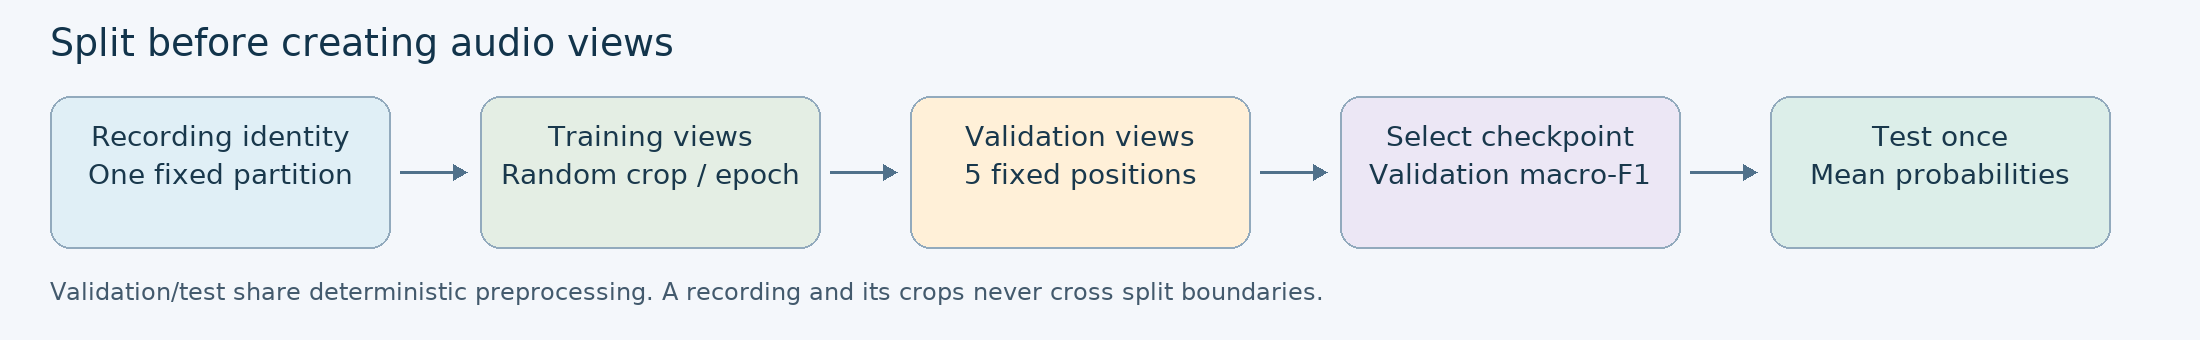

## 5. Dataset overview

Class counts show imbalance; recording durations show the range of available audio. Partition counts check class coverage across the fixed split. Audit tables list invalid and duplicate recordings. These plots describe the dataset; detailed signal examples below use training recordings only.

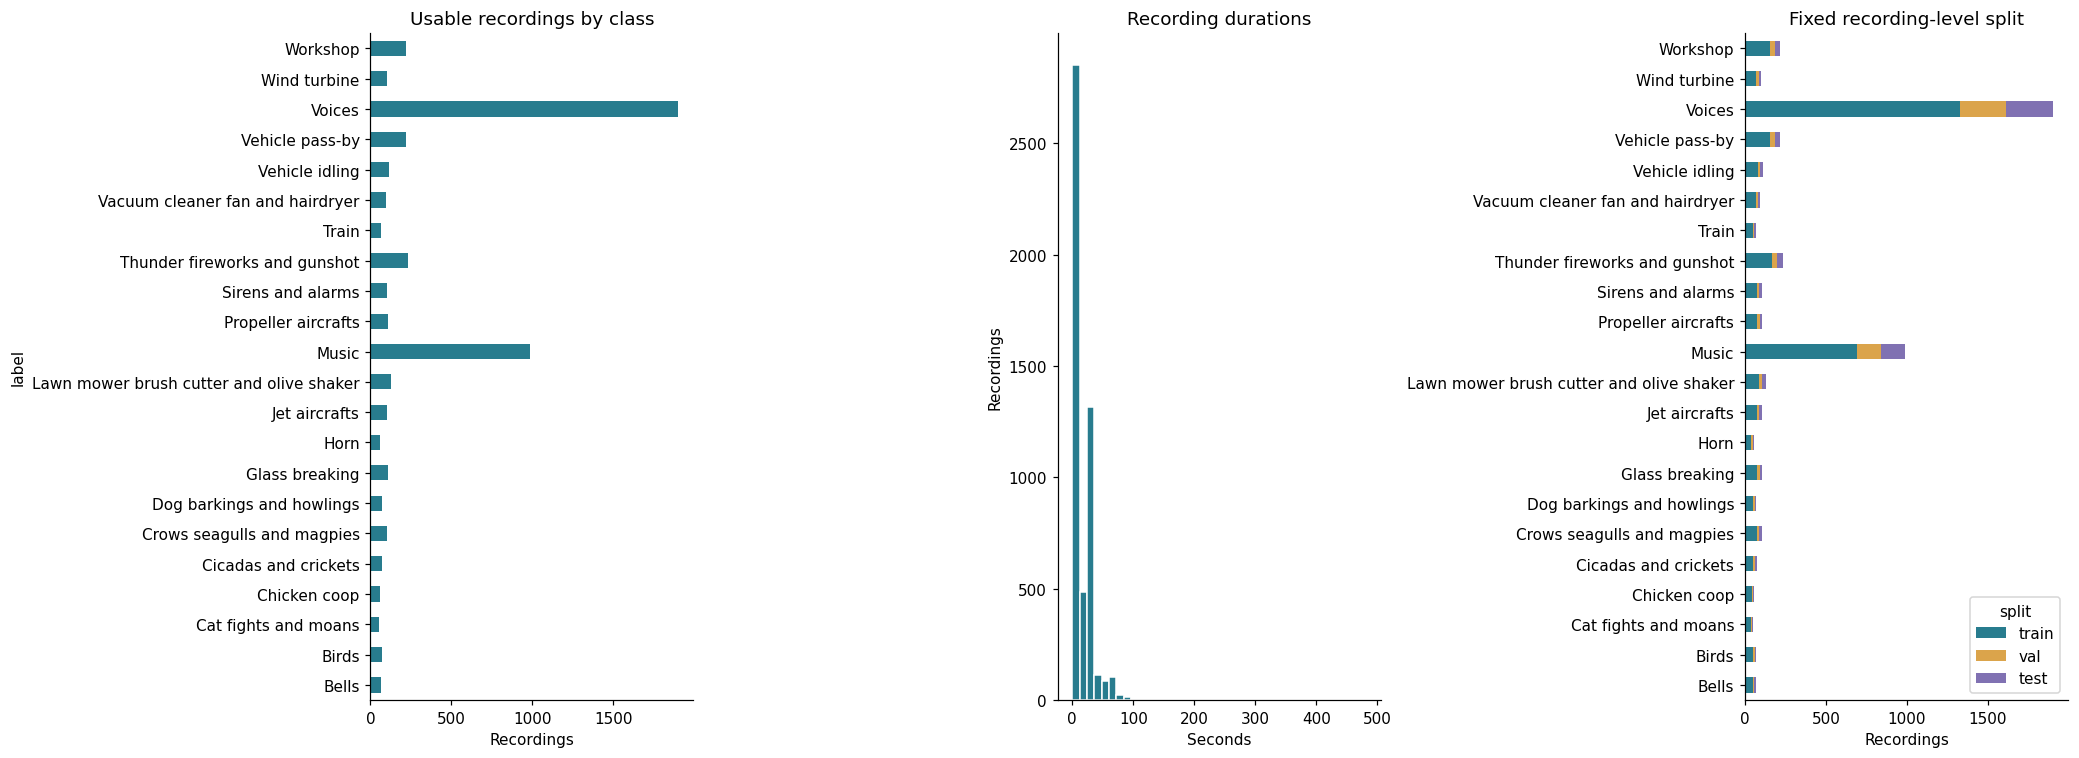

split,train,val,test,total
label,,,,
Bells,47,10,10,67
Birds,48,11,10,69
Cat fights and moans,35,8,7,50
Chicken coop,41,8,9,58
Cicadas and crickets,52,11,11,74
Crows seagulls and magpies,73,16,16,105
Dog barkings and howlings,49,10,11,70
Glass breaking,76,16,16,108
Horn,40,8,9,57


Usable audio hours: 23.583998973293014
invalid_audio.csv : 0 rows


,relative_path,label,error,audio_hash,duration,sample_rate,channels


duplicate_audio.csv : 16 rows


,relative_path,label,error,audio_hash,duration,sample_rate,channels
0,Crows seagulls and magpies/Crows/Crows-0050.wav,Crows seagulls and magpies,NaN,9d01a713da9a32aedbc7a874aa6cb6baa20857e21717fd...,17.833356,44100,1
1,Glass breaking/Glass breaking-0098.wav,Glass breaking,NaN,4dd7c5ac84be7e14f6f26a8f7cc0089c178bf8b644065a...,8.679161,44100,1
2,Music/Music-0400.wav,Music,NaN,585fc404680b7eda5a87b7afd548965485223959a114dc...,30.000181,44100,1
3,Music/Music-0446.wav,Music,NaN,22c5edb0915dc86feca87e92e6cc220feb3d501e3b350d...,30.648889,44100,1
4,Music/Music-0479.wav,Music,NaN,511660221b61849b4e9ef520294c8c2efaca445c87b356...,30.000181,44100,1


,,recordings
sample_rate,channels,
44100,1,5048


In [11]:
counts = frame.label.value_counts().reindex(class_names)
split_counts = pd.crosstab(frame.label, frame.split).reindex(
    index=class_names, columns=["train", "val", "test"], fill_value=0
)
fig, axes = plt.subplots(1, 3, figsize=(19, 7))
counts.plot.barh(ax=axes[0], color="#287c8e", title="Usable recordings by class")
axes[0].set_xlabel("Recordings")
axes[1].hist(frame.duration, bins=40, color="#287c8e", edgecolor="white")
axes[1].set(title="Recording durations", xlabel="Seconds", ylabel="Recordings")
split_counts.plot.barh(
    stacked=True, ax=axes[2], color=["#287c8e", "#dba44b", "#8071b2"]
)
axes[2].set(title="Fixed recording-level split", xlabel="Recordings", ylabel="")
fig.tight_layout()
fig.savefig(FIGURES / "dataset_overview.png", bbox_inches="tight")
plt.show()
display(split_counts.assign(total=split_counts.sum(axis=1)))
print("Usable audio hours:", frame.duration.sum() / 3600)
for name in ["invalid_audio.csv", "duplicate_audio.csv"]:
    rows = pd.read_csv(AUDIT_DIR / name)
    print(name, ":", len(rows), "rows")
    display(rows.head())
display(
    inventory.groupby(["sample_rate", "channels"])
    .size()
    .rename("recordings")
    .to_frame()
)


## 6. Audio preprocessing and training examples

Audio is converted to mono and resampled to the checkpoint's 16 kHz input. The feature extractor uses 25 ms frames, 10 ms hops, 128 Mel bins and 1,024 frames per input. AudioSet normalization is applied as `(features - mean) / (2 × std)`; no statistics are fitted on test recordings.

Training uses one random view of approximately 10.255 seconds per recording. Validation and test average probabilities from five evenly spaced views. Short inputs are padded; long recordings are sampled rather than covered exhaustively. The plots show the normalized features actually passed to AST.

In [12]:
def load_audio(path, sample_rate):
    x, sr = sf.read(path, dtype="float32", always_2d=True)
    if not len(x) or not np.isfinite(x).all():
        raise ValueError(f"Invalid audio at runtime: {path}")
    x = x.mean(axis=1)
    if sr != sample_rate:
        g = math.gcd(sr, sample_rate)
        x = resample_poly(x, sample_rate // g, sr // g).astype(np.float32)
    return np.ascontiguousarray(x)


def features(x, extractor, training=False, eval_crops=5):
    n = round((0.025 + 0.01 * (extractor.max_length - 1)) * extractor.sampling_rate)
    last = max(0, len(x) - n)
    starts = (
        [np.random.randint(last + 1)]
        if training
        else np.linspace(0, last, eval_crops).round().astype(int)
    )
    clips = []
    for start in starts:
        clip = np.array(x[int(start) : int(start) + n], dtype=np.float32, copy=True)
        clip = np.pad(
            clip, (0, max(0, round(0.025 * extractor.sampling_rate) - len(clip)))
        )
        clips.append(clip)
    result = extractor(
        clips, sampling_rate=extractor.sampling_rate, return_tensors="pt"
    )["input_values"]
    if not torch.isfinite(result).all():
        raise ValueError("Nonfinite AST features")
    return result


In [13]:
extractor = ASTFeatureExtractor.from_pretrained(CHECKPOINT_PATH, revision=REVISION)
display(
    pd.Series(
        {
            key: getattr(extractor, key)
            for key in [
                "sampling_rate",
                "num_mel_bins",
                "max_length",
                "mean",
                "std",
                "do_normalize",
            ]
        },
        name="Checkpoint preprocessing",
    ).to_frame()
)


preprocessor_config.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

,Checkpoint preprocessing
sampling_rate,16000
num_mel_bins,128
max_length,1024
mean,-4.267739
std,4.568997
do_normalize,True


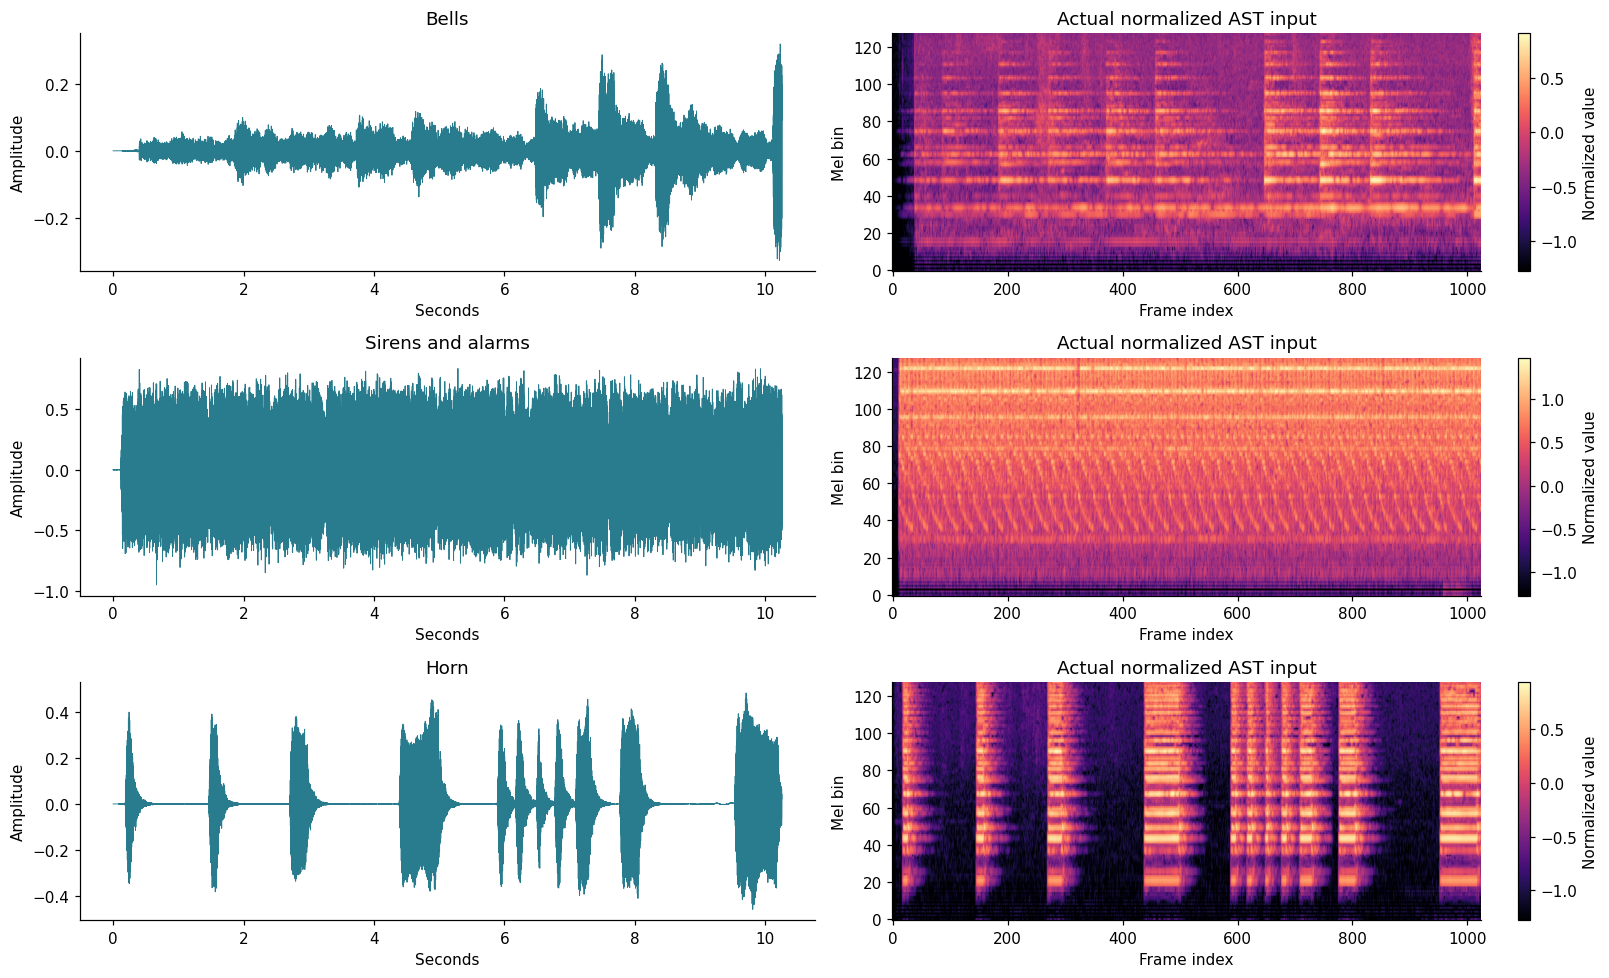

**Training audio example: Bells**

In [14]:
examples = (
    partitions["train"]
    .groupby("label", group_keys=False)
    .head(1)
    .sample(n=3, random_state=CFG["seed"])
)
fig, axes = plt.subplots(3, 2, figsize=(15, 9))
for i, row in enumerate(examples.itertuples()):
    wave = load_audio(DATA_DIR / row.relative_path, extractor.sampling_rate)
    n = round((0.025 + 0.010 * (extractor.max_length - 1)) * extractor.sampling_rate)
    shown = wave[:n]
    tensor = features(wave, extractor, False, 1)[0].numpy()
    axes[i, 0].plot(
        np.arange(len(shown)) / extractor.sampling_rate, shown, lw=0.6, color="#287c8e"
    )
    axes[i, 0].set(title=row.label, xlabel="Seconds", ylabel="Amplitude")
    im = axes[i, 1].imshow(tensor.T, aspect="auto", origin="lower", cmap="magma")
    axes[i, 1].set(
        title="Actual normalized AST input", xlabel="Frame index", ylabel="Mel bin"
    )
    fig.colorbar(im, ax=axes[i, 1], label="Normalized value")
fig.tight_layout()
fig.savefig(FIGURES / "training_audio_features.png", bbox_inches="tight")
plt.show()
first_example = examples.iloc[0]
display(Markdown("**Training audio example: " + first_example.label + "**"))
display(
    Audio(
        load_audio(DATA_DIR / first_example.relative_path, extractor.sampling_rate)[
            : 10 * extractor.sampling_rate
        ],
        rate=extractor.sampling_rate,
    )
)


## 7. Audio Spectrogram Transformer

AST divides the spectrogram into overlapping patches, projects them into embeddings, and adds positional embeddings plus classification and distillation tokens. Transformer layers use self-attention to relate information across time and frequency:

$$\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\left(\frac{QK^\mathsf{T}}{\sqrt{d_k}}\right)V.$$

Here, $Q$, $K$ and $V$ are the query, key and value projections, and $d_k$ is the key dimension per attention head. The final classification and distillation representations are averaged before classification. The pretrained AudioSet head is replaced with 22 outputs for single-label cross-entropy training.

The default fine-tunes all layers with gradient checkpointing to reduce activation memory. `FINE_TUNE_SCOPE='head'` provides a separate frozen-backbone baseline. Unlike SincNet trained from scratch, this model benefits from AudioSet pretraining; that difference belongs in any performance comparison.

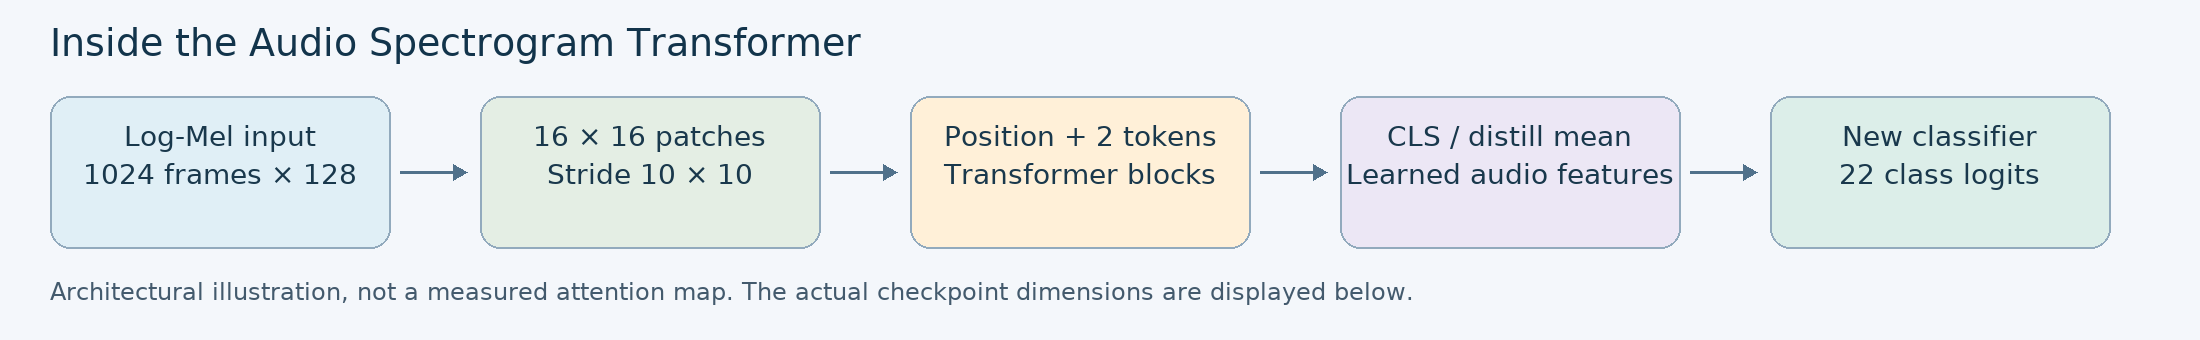

config.json: 0.00B [00:00, ?B/s]

,Actual checkpoint architecture
patch_size,16
frequency_stride,10
time_stride,10
frequency_positions,12
time_positions,101
patch_tokens,1212
total_tokens,1214
transformer_layers,12
attention_heads,12
hidden_size,768


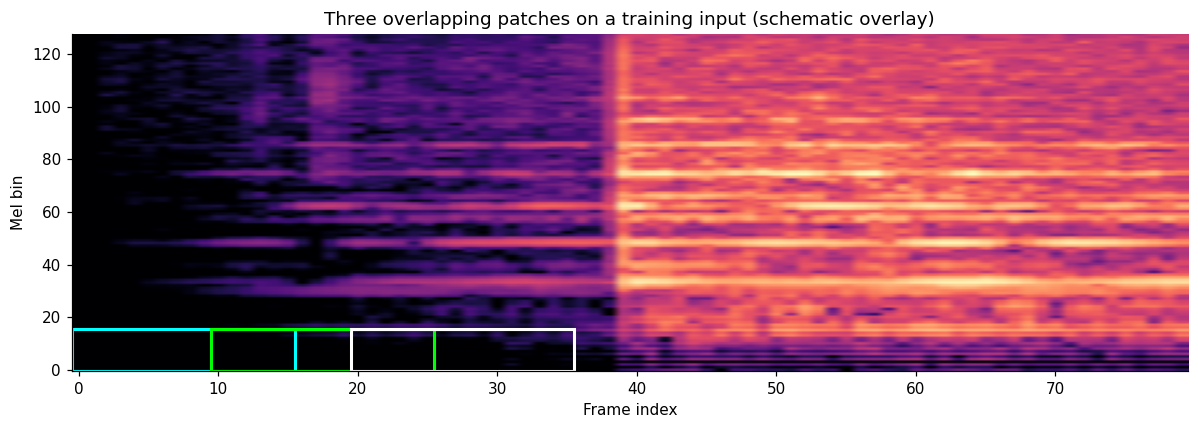

In [15]:
architecture_config = ASTConfig.from_pretrained(CHECKPOINT_PATH, revision=REVISION)
patch = architecture_config.patch_size
fs, ts = architecture_config.frequency_stride, architecture_config.time_stride
fp = (architecture_config.num_mel_bins - patch) // fs + 1
tp = (architecture_config.max_length - patch) // ts + 1
display(
    pd.Series(
        dict(
            patch_size=patch,
            frequency_stride=fs,
            time_stride=ts,
            frequency_positions=fp,
            time_positions=tp,
            patch_tokens=fp * tp,
            total_tokens=fp * tp + 2,
            transformer_layers=architecture_config.num_hidden_layers,
            attention_heads=architecture_config.num_attention_heads,
            hidden_size=architecture_config.hidden_size,
        ),
        name="Actual checkpoint architecture",
    ).to_frame()
)
patch_example = features(
    load_audio(DATA_DIR / first_example.relative_path, extractor.sampling_rate),
    extractor,
    False,
    1,
)[0].numpy()
fig, ax = plt.subplots(figsize=(11, 4))
ax.imshow(
    patch_example[: min(80, len(patch_example))].T,
    origin="lower",
    aspect="auto",
    cmap="magma",
)
for j, color in enumerate(["cyan", "lime", "white"]):
    ax.add_patch(
        Rectangle((j * ts - 0.5, -0.5), patch, patch, fill=False, edgecolor=color, lw=2)
    )
ax.set(
    title="Three overlapping patches on a training input (schematic overlay)",
    xlabel="Frame index",
    ylabel="Mel bin",
)
fig.tight_layout()
fig.savefig(FIGURES / "patch_overlay.png", bbox_inches="tight")
plt.show()


In [16]:
def setup_model(mapping, checkpoint=CHECKPOINT_PATH, revision=None, scope="full"):
    kwargs = {"revision": revision} if revision else {}
    try:
        extractor = ASTFeatureExtractor.from_pretrained(checkpoint, **kwargs)
        model, info = ASTForAudioClassification.from_pretrained(
            checkpoint,
            num_labels=22,
            label2id=mapping,
            id2label={v: k for k, v in mapping.items()},
            ignore_mismatched_sizes=True,
            output_loading_info=True,
            use_safetensors=True,
            attn_implementation="sdpa",
            **kwargs,
        )
    except Exception as e:
        raise RuntimeError(
            "Cannot load AST checkpoint. Enable Kaggle Internet or set checkpoint to an attached local Hugging Face snapshot with config, preprocessor and safetensors weights."
        ) from e
    mismatched = [
        item if isinstance(item, str) else item[0]
        for item in info.get("mismatched_keys", [])
    ]
    missing = list(info.get("missing_keys", []) or [])
    if any((not k.startswith("classifier.") for k in mismatched + missing)):
        raise RuntimeError(f"Unexpected missing backbone weights: {info}")
    if (
        extractor.max_length != model.config.max_length
        or extractor.num_mel_bins != model.config.num_mel_bins
    ):
        raise ValueError("Checkpoint feature dimensions do not match patch positions")
    if scope not in ["full", "head"]:
        raise ValueError("scope must be full or head")
    if scope == "head":
        for p in model.audio_spectrogram_transformer.parameters():
            p.requires_grad_(False)
    else:
        model.gradient_checkpointing_enable(
            gradient_checkpointing_kwargs={"use_reentrant": False}
        )
    print(
        "Feature shape:",
        extractor.max_length,
        extractor.num_mel_bins,
        "sample rate:",
        extractor.sampling_rate,
    )
    print(
        "Fine-tuning scope:",
        scope,
        "Parameters:",
        sum((p.numel() for p in model.parameters())),
        "trainable:",
        sum((p.numel() for p in model.parameters() if p.requires_grad)),
    )
    return (model, extractor)


## 8. Dataset and data loaders

Each item contains one recording's feature views and its class ID. Batch dimensions are `[recordings, crops, frames, Mel bins]`. Only individual recordings are decoded; optional disk caching stores resampled audio by decoded hash and sample rate. Preprocessing failures name the recording and stop instead of silently changing dataset membership.

The first batch checks feature dimensions and finite values before training. Workers default to zero for reliable notebook execution.

In [17]:
class AudioDataset(Dataset):

    def __init__(
        self, frame, root, extractor, training=False, eval_crops=5, cache=None
    ):
        self.rows = frame.to_dict("records")
        self.root = Path(root)
        self.extractor = extractor
        self.training = training
        self.eval_crops = eval_crops
        self.cache = Path(cache) if cache else None
        if self.cache:
            self.cache.mkdir(parents=True, exist_ok=True)

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        r = self.rows[i]
        try:
            cache = (
                self.cache / f"{r['audio_hash']}_{self.extractor.sampling_rate}.npy"
                if self.cache
                else None
            )
            if cache and cache.exists():
                x = np.load(cache, mmap_mode="r", allow_pickle=False)
            else:
                x = load_audio(
                    self.root / r["relative_path"], self.extractor.sampling_rate
                )
                if cache:
                    import os

                    temp = cache.with_name(cache.name + f".{os.getpid()}.tmp")
                    with temp.open("wb") as f:
                        np.save(f, x, allow_pickle=False)
                    temp.replace(cache)
            return (
                features(x, self.extractor, self.training, self.eval_crops),
                int(r["target"]),
            )
        except Exception as e:
            raise RuntimeError(
                f"Audio preprocessing failed: {r['relative_path']}; no silent skipping"
            ) from e


def seed_worker(_):
    seed = torch.initial_seed() % 2**32
    np.random.seed(seed)
    random.seed(seed)


def loader(frame, root, extractor, cfg, training=False, epoch=0):
    ds = AudioDataset(
        frame, root, extractor, training, cfg["eval_crops"], cfg.get("cache")
    )
    return DataLoader(
        ds,
        batch_size=cfg["batch_size"],
        shuffle=training,
        num_workers=cfg["workers"],
        pin_memory=torch.cuda.is_available(),
        worker_init_fn=seed_worker,
        generator=torch.Generator().manual_seed(cfg["seed"] + epoch),
    )


In [18]:
batch, labels = next(
    iter(
        loader(
            partitions["train"].head(2),
            DATA_DIR,
            extractor,
            {**CFG, "workers": 0},
            training=True,
        )
    )
)
print("Training features:", tuple(batch.shape), "| targets:", labels.tolist())
assert batch.shape[-2:] == (extractor.max_length, extractor.num_mel_bins)
assert torch.isfinite(batch).all()
del batch


Training features: (1, 1, 1024, 128) | targets: [0]


## 9. Training, validation and checkpoint selection

AdamW, cosine learning-rate scheduling, sample-weighted gradient accumulation and gradient clipping define optimization. CUDA mixed precision reduces memory use. Actual optimizer updates are counted because overflow can skip a step; an epoch with no updates fails explicitly.

Validation macro-F1 selects `best.pt`; `last.pt` records the last completed epoch and optimizer state. All 22 classes are included in macro metrics. Training loss is single-view cross-entropy, while validation loss is negative log likelihood after averaging crop probabilities. The curves therefore compare related but different objectives. These functions do not use test recordings for optimization.

In [19]:
def scores(y, pred):
    p, r, f, _ = precision_recall_fscore_support(
        y, pred, labels=list(range(22)), average="macro", zero_division=0
    )
    return dict(
        accuracy=float(accuracy_score(y, pred)),
        macro_precision=float(p),
        macro_recall=float(r),
        macro_f1=float(f),
    )


def sync(device):
    if device.type == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def evaluate(model, batches, device, amp=False):
    model.eval()
    ys = []
    probs = []
    loss_sum = 0.0
    forward_seconds = 0.0
    start = time.perf_counter()
    for x, y in batches:
        b, c, t, f = x.shape
        x = x.to(device)
        y = y.to(device)
        total = 0
        for j in range(c):
            sync(device)
            tick = time.perf_counter()
            with torch.autocast(device_type=device.type, enabled=amp):
                logits = model(input_values=x[:, j]).logits
            sync(device)
            forward_seconds += time.perf_counter() - tick
            total = total + logits.float().softmax(-1)
        probability = total / c
        loss_sum += torch.nn.functional.nll_loss(
            probability.clamp_min(1e-12).log(), y, reduction="sum"
        ).item()
        ys.extend(y.cpu().tolist())
        probs.extend(probability.cpu().numpy())
    prob = np.array(probs)
    pred = prob.argmax(1)
    result = scores(ys, pred)
    result.update(
        loss=loss_sum / len(ys),
        recordings=len(ys),
        forward_ms_per_recording=1000 * forward_seconds / len(ys),
        end_to_end_ms_per_recording=1000 * (time.perf_counter() - start) / len(ys),
    )
    return (result, np.asarray(ys), prob)


def save_evaluation(out, frame, mapping, result, y, prob):
    out = Path(out)
    final_out = out
    if final_out.exists():
        raise FileExistsError(f"Test results already exist: {final_out}")
    import tempfile

    out.parent.mkdir(parents=True, exist_ok=True)
    out = Path(tempfile.mkdtemp(prefix="." + out.name + "_staging_", dir=out.parent))
    names = [k for k, v in sorted(mapping.items(), key=lambda kv: kv[1])]
    pred = prob.argmax(1)
    report = classification_report(
        y,
        pred,
        labels=list(range(22)),
        target_names=names,
        zero_division=0,
        output_dict=True,
    )
    pd.DataFrame(report).T.to_csv(out / "classification_report.csv")
    cm = confusion_matrix(y, pred, labels=list(range(22)))
    pd.DataFrame(cm, index=names, columns=names).to_csv(out / "confusion_matrix.csv")
    fig, ax = plt.subplots(figsize=(15, 13))
    im = ax.imshow(cm, cmap="Blues")
    fig.colorbar(im, ax=ax)
    ax.set(
        xticks=range(22),
        yticks=range(22),
        xticklabels=names,
        yticklabels=names,
        xlabel="Predicted",
        ylabel="True",
    )
    plt.setp(ax.get_xticklabels(), rotation=90)
    fig.tight_layout()
    fig.savefig(out / "confusion_matrix.png", dpi=150)
    plt.close(fig)
    rows = frame[["relative_path", "label", "target"]].copy()
    rows["prediction"] = pred
    rows["score"] = prob.max(1)
    for i, name in enumerate(names):
        rows[f"prob_{name}"] = prob[:, i]
    rows.to_csv(out / "predictions.csv", index=False)
    rows[rows.target != rows.prediction].to_csv(out / "errors.csv", index=False)
    (out / "metrics.json").write_text(json.dumps(result, indent=2))
    out.rename(final_out)


def curves(history, out):
    h = pd.DataFrame(history)
    h.to_csv(Path(out) / "history.csv", index=False)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, key in zip(axes, ["loss", "accuracy", "macro_f1"]):
        for s in ["train", "val"]:
            ax.plot(h.epoch, h[f"{s}_{key}"], label=s)
        ax.set(title=key, xlabel="Epoch")
        ax.legend()
    fig.tight_layout()
    fig.savefig(Path(out) / "training_curves.png", dpi=150)
    plt.close(fig)


@torch.no_grad()
def predict_wav(path, model, extractor, mapping, device, eval_crops=5):
    model.eval()
    x = features(
        load_audio(path, extractor.sampling_rate), extractor, False, eval_crops
    )
    prob = torch.stack(
        [
            model(input_values=crop[None].to(device)).logits.float().softmax(-1)[0]
            for crop in x
        ]
    ).mean(0)
    values, ids = prob.topk(3)
    inverse = {v: k for k, v in mapping.items()}
    top = [
        dict(class_id=int(i), label=inverse[int(i)], score=float(v))
        for i, v in zip(ids, values)
    ]
    return dict(
        path=str(path),
        **top[0],
        top_three=top,
        interpretation="Uncalibrated mean softmax score; recording classification demo",
    )


In [20]:
def fingerprint(frame):
    return hashlib.sha256(
        frame.sort_values("relative_path").to_csv(index=False).encode()
    ).hexdigest()


def atomic_save(payload, path):
    path = Path(path)
    tmp = path.with_suffix(".tmp")
    torch.save(payload, tmp)
    tmp.replace(path)


def train(model, extractor, frame, mapping, root, out, cfg, smoke=False):
    if (
        any(
            (
                cfg[k] < 1
                for k in [
                    "batch_size",
                    "accumulation",
                    "epochs",
                    "patience",
                    "eval_crops",
                ]
            )
        )
        or cfg["workers"] < 0
        or cfg["lr"] <= 0
    ):
        raise ValueError(
            "Batch/accumulation/epochs/patience/crops/LR must be positive; workers must be nonnegative"
        )
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    if (out / "last.pt").exists():
        raise FileExistsError("Run exists; choose a new output directory")
    if any(out.iterdir()):
        raise FileExistsError("New training requires an empty output directory")
    seed_all(cfg["seed"])
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    amp = device.type == "cuda" and cfg["amp"]
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(
        params, lr=cfg["lr"], weight_decay=cfg["weight_decay"]
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=cfg["epochs"]
    )
    scaler = torch.amp.GradScaler("cuda", enabled=amp, init_scale=1024.0)
    completed_steps = [0]

    def count_step(optimizer, args, kwargs):
        completed_steps[0] += 1

    step_hook = optimizer.register_step_post_hook(count_step)
    history = []
    best = -1.0
    stale = 0
    first = 0
    elapsed = 0.0
    signature = fingerprint(frame)
    extractor.save_pretrained(out / "processor")
    model.config.save_pretrained(out / "model_config")
    (out / "config.json").write_text(
        json.dumps(
            dict(
                cfg=cfg,
                mapping=mapping,
                fingerprint=signature,
                smoke=smoke,
                environment=environment(),
            ),
            indent=2,
        )
    )
    frame.to_csv(out / "split_manifest.csv", index=False)
    (out / "class_mapping.json").write_text(json.dumps(mapping, indent=2))
    tr = frame[frame.split == "train"].reset_index(drop=True)
    va = frame[frame.split == "val"].reset_index(drop=True)
    if smoke:
        tr = tr.groupby("target", group_keys=False).head(1).head(4)
        va = va.groupby("target", group_keys=False).head(1).head(4)
    val_loader = loader(va, root, extractor, cfg)
    for epoch in range(first, cfg["epochs"]):
        if stale >= cfg["patience"]:
            break
        tick = time.perf_counter()
        batches = loader(tr, root, extractor, cfg, True, epoch)
        completed_steps[0] = 0
        attempted_steps = 0
        model.train()
        if cfg["scope"] == "head":
            model.audio_spectrogram_transformer.eval()
        optimizer.zero_grad(set_to_none=True)
        ys = []
        preds = []
        loss_sum = 0.0
        window_count = 0
        for step, (x, y) in enumerate(batches):
            x = x[:, 0].to(device)
            y = y.to(device)
            with torch.autocast(device_type=device.type, enabled=amp):
                logits = model(input_values=x).logits
                loss = torch.nn.functional.cross_entropy(logits, y, reduction="sum")
            if not torch.isfinite(loss):
                raise RuntimeError("Nonfinite loss; inspect inputs and learning rate")
            scaler.scale(loss).backward()
            window_count += len(y)
            loss_sum += loss.item()
            ys.extend(y.cpu().tolist())
            preds.extend(logits.argmax(-1).detach().cpu().tolist())
            if (step + 1) % cfg["accumulation"] == 0 or step + 1 == len(batches):
                scaler.unscale_(optimizer)
                for p in params:
                    if p.grad is not None:
                        p.grad.div_(window_count)
                torch.nn.utils.clip_grad_norm_(params, 1.0, error_if_nonfinite=not amp)
                attempted_steps += 1
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                window_count = 0
            if (step + 1) % 100 == 0:
                print(
                    f"Epoch {epoch + 1}: batch {step + 1}/{len(batches)}, optimizer updates={completed_steps[0]}",
                    flush=True,
                )
        if completed_steps[0] == 0:
            raise RuntimeError(
                "No optimizer updates completed. Mixed precision may have overflowed. Rerun the smoke test in a NEW directory with amp=False and batch_size=1; no checkpoint was saved for this epoch."
            )
        tm = scores(ys, preds)
        tm["loss"] = loss_sum / len(ys)
        vm, _, _ = evaluate(model, val_loader, device, amp)
        row = dict(
            epoch=epoch + 1,
            lr=optimizer.param_groups[0]["lr"],
            seconds=time.perf_counter() - tick,
            optimizer_updates=completed_steps[0],
            skipped_updates=attempted_steps - completed_steps[0],
        )
        row.update({f"train_{k}": v for k, v in tm.items()})
        row.update({f"val_{k}": v for k, v in vm.items()})
        history.append(row)
        elapsed += row["seconds"]
        scheduler.step()
        improved = vm["macro_f1"] > best
        if improved:
            best = vm["macro_f1"]
            stale = 0
        else:
            stale += 1
        state = dict(
            model=model.state_dict(),
            optimizer=optimizer.state_dict(),
            scheduler=scheduler.state_dict(),
            scaler=scaler.state_dict(),
            epoch=epoch,
            best=best,
            stale=stale,
            history=history,
            elapsed=elapsed,
            cfg=cfg,
            mapping=mapping,
            fingerprint=signature,
            smoke=smoke,
            rng_python=random.getstate(),
            rng_numpy=np.random.get_state(),
            rng_torch=torch.get_rng_state(),
            rng_cuda=(
                torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None
            ),
        )
        if improved:
            atomic_save(
                dict(
                    model=model.state_dict(),
                    epoch=epoch,
                    best=best,
                    mapping=mapping,
                    cfg=cfg,
                    fingerprint=signature,
                    smoke=smoke,
                ),
                out / "best.pt",
            )
        atomic_save(state, out / "last.pt")
        curves(history, out)
        print(
            f"Epoch {epoch + 1}: train loss={tm['loss']:.4f} F1={tm['macro_f1']:.4f}; val loss={vm['loss']:.4f} accuracy={vm['accuracy']:.4f} F1={vm['macro_f1']:.4f}; best={best:.4f}",
            flush=True,
        )
    step_hook.remove()
    return history


def load_best(out, device):
    from transformers import ASTConfig, ASTFeatureExtractor, ASTForAudioClassification

    out = Path(out)
    state = torch.load(out / "best.pt", map_location="cpu", weights_only=False)
    config = ASTConfig.from_pretrained(out / "model_config")
    model = ASTForAudioClassification(config)
    model.load_state_dict(state["model"])
    model.to(device).eval()
    return (model, ASTFeatureExtractor.from_pretrained(out / "processor"), state)


## 10. Smoke test

Four training and four validation recordings are used for one full-precision epoch in a separate folder. This checks optimization, checkpoint save/reload and WAV prediction before the full experiment. Smoke-test scores are debugging outputs, not project results. Full training starts again from pretrained weights.

In [21]:
if RUN_SMOKE_TEST and MODE == "new":
    SMOKE = OUTPUT / f"smoke_run_{datetime.now():%Y%m%d_%H%M%S_%f}"
    seed_all(CFG["seed"])
    smoke_model, smoke_extractor = setup_model(
        mapping, CHECKPOINT_PATH, REVISION, CFG["scope"]
    )
    smoke_cfg = {
        **CFG,
        "epochs": 1,
        "workers": 0,
        "batch_size": 1,
        "accumulation": 2,
        "eval_crops": 1,
        "amp": False,
    }
    smoke_history = train(
        smoke_model,
        smoke_extractor,
        frame,
        mapping,
        DATA_DIR,
        SMOKE,
        smoke_cfg,
        smoke=True,
    )
    assert smoke_history[0]["optimizer_updates"] > 0
    smoke_model.zero_grad(set_to_none=True)
    del smoke_model
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    smoke_model, smoke_extractor, smoke_state = load_best(SMOKE, DEVICE)
    print(
        predict_wav(
            DATA_DIR / partitions["val"].iloc[0].relative_path,
            smoke_model,
            smoke_extractor,
            mapping,
            DEVICE,
            1,
        )
    )
    del smoke_model, smoke_extractor, smoke_state
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    print("Smoke check passed:", SMOKE)
else:
    print("Smoke execution skipped by mode/configuration; no new smoke result claimed.")


model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Some weights of ASTForAudioClassification were not initialized from the model checkpoint at MIT/ast-finetuned-audioset-10-10-0.4593 and are newly initialized because the shapes did not match:
- classifier.dense.bias: found shape torch.Size([527]) in the checkpoint and torch.Size([22]) in the model instantiated
- classifier.dense.weight: found shape torch.Size([527, 768]) in the checkpoint and torch.Size([22, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Feature shape: 1024 128 sample rate: 16000
Fine-tuning scope: full Parameters: 86205718 trainable: 86205718
{'python': '3.13.15', 'torch': '2.11.0+cu128', 'transformers': '4.57.1', 'torchaudio': '2.11.0+cu128', 'numpy': '2.1.3', 'scipy': '1.16.3', 'soundfile': '0.14.0', 'scikit-learn': '1.6.1', 'device': 'Tesla T4', 'gpu_free_gib': 14.07110595703125, 'gpu_total_gib': 14.56219482421875}


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 1: train loss=3.6174 F1=0.0000; val loss=2.7992 accuracy=0.2500 F1=0.0455; best=0.0455
{'path': '/kaggle/working/datasec_download/extracted/DATASEC/Bells/Bells-0003.wav', 'class_id': 0, 'label': 'Bells', 'score': 0.13353829085826874, 'top_three': [{'class_id': 0, 'label': 'Bells', 'score': 0.13353829085826874}, {'class_id': 10, 'label': 'Lawn mower brush cutter and olive shaker', 'score': 0.11427509039640427}, {'class_id': 14, 'label': 'Thunder fireworks and gunshot', 'score': 0.07670731097459793}], 'interpretation': 'Uncalibrated mean softmax score; recording classification demo'}
Smoke check passed: /kaggle/working/ast_datasec/smoke_run_20261029_160819_691739


## 11. Full training and learning curves

Each epoch trains on random recording views and then validates on fixed views. Early stopping and checkpoint selection use validation macro-F1 only. The dashed line marks the first epoch achieving the best validation score. Inspect the measured curves before attributing a pattern to overfitting.

In [22]:
seed_all(CFG["seed"])
model, extractor = setup_model(mapping, CHECKPOINT_PATH, REVISION, CFG["scope"])
history = train(model, extractor, frame, mapping, DATA_DIR, RUN, CFG)
model.zero_grad(set_to_none=True)
del model
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()


Some weights of ASTForAudioClassification were not initialized from the model checkpoint at MIT/ast-finetuned-audioset-10-10-0.4593 and are newly initialized because the shapes did not match:
- classifier.dense.bias: found shape torch.Size([527]) in the checkpoint and torch.Size([22]) in the model instantiated
- classifier.dense.weight: found shape torch.Size([527, 768]) in the checkpoint and torch.Size([22, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Feature shape: 1024 128 sample rate: 16000
Fine-tuning scope: full Parameters: 86205718 trainable: 86205718
{'python': '3.13.15', 'torch': '2.11.0+cu128', 'transformers': '4.57.1', 'torchaudio': '2.11.0+cu128', 'numpy': '2.1.3', 'scipy': '1.16.3', 'soundfile': '0.14.0', 'scikit-learn': '1.6.1', 'device': 'Tesla T4', 'gpu_free_gib': 13.93829345703125, 'gpu_total_gib': 14.56219482421875}


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 1: batch 100/3522, optimizer updates=6
Epoch 1: batch 200/3522, optimizer updates=12
Epoch 1: batch 300/3522, optimizer updates=18
Epoch 1: batch 400/3522, optimizer updates=25
Epoch 1: batch 500/3522, optimizer updates=31
Epoch 1: batch 600/3522, optimizer updates=37
Epoch 1: batch 700/3522, optimizer updates=43
Epoch 1: batch 800/3522, optimizer updates=50
Epoch 1: batch 900/3522, optimizer updates=56
Epoch 1: batch 1000/3522, optimizer updates=62
Epoch 1: batch 1100/3522, optimizer updates=68
Epoch 1: batch 1200/3522, optimizer updates=75
Epoch 1: batch 1300/3522, optimizer updates=81
Epoch 1: batch 1400/3522, optimizer updates=87
Epoch 1: batch 1500/3522, optimizer updates=93
Epoch 1: batch 1600/3522, optimizer updates=100
Epoch 1: batch 1700/3522, optimizer updates=106
Epoch 1: batch 1800/3522, optimizer updates=112
Epoch 1: batch 1900/3522, optimizer updates=118
Epoch 1: batch 2000/3522, optimizer updates=125
Epoch 1: batch 2100/3522, optimizer updates=131
Epoch 1: batch 22

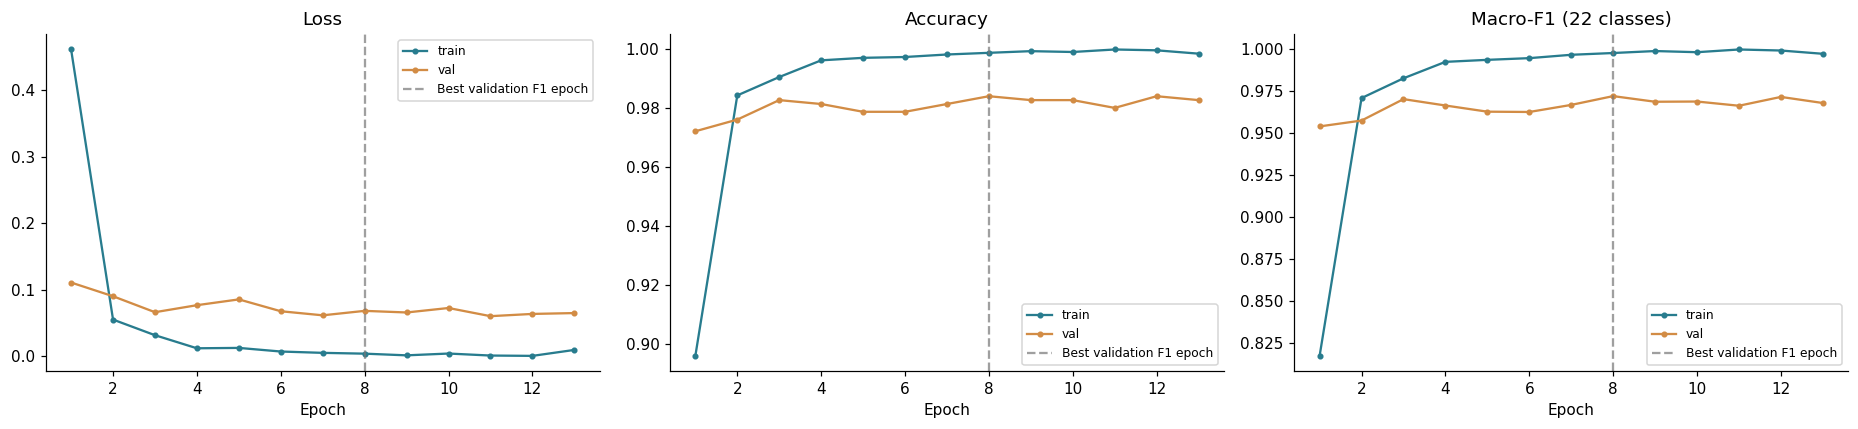

,epoch,lr,seconds,optimizer_updates,skipped_updates,train_accuracy,train_macro_precision,train_macro_recall,train_macro_f1,train_loss,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_loss,val_recordings,val_forward_ms_per_recording,val_end_to_end_ms_per_recording
0,1,1.000000e-05,603.456542,221,0,0.895798,0.877041,0.778138,0.817235,0.461489,0.972185,0.959778,0.952722,0.954113,0.110941,755,119.977528,168.757825
1,2,9.890738e-06,599.332888,221,0,0.984384,0.969559,0.972694,0.971019,0.055221,0.976159,0.966499,0.956521,0.957608,0.090307,755,120.489394,168.581722
2,3,9.567727e-06,595.669406,221,0,0.990630,0.982412,0.983399,0.982817,0.031735,0.982781,0.972599,0.971346,0.970386,0.066320,755,119.746998,167.151387
3,4,9.045085e-06,591.922676,221,0,0.996309,0.992944,0.992370,0.992622,0.012056,0.981457,0.971074,0.965906,0.966587,0.076879,755,118.281845,165.029404
4,5,8.345653e-06,590.465768,221,0,0.997161,0.994931,0.992801,0.993823,0.012623,0.978808,0.964442,0.964113,0.962904,0.085591,755,118.595018,165.368808
5,6,7.500000e-06,593.428057,221,0,0.997445,0.995170,0.994577,0.994836,0.007185,0.978808,0.961221,0.966229,0.962725,0.067767,755,120.479767,168.024532
6,7,6.545085e-06,592.238872,221,0,0.998296,0.996644,0.997044,0.996838,0.005175,0.981457,0.966365,0.968947,0.966943,0.061639,755,119.484703,166.791627
7,8,5.522642e-06,593.201818,221,0,0.998864,0.997341,0.998472,0.997894,0.003967,0.984106,0.973276,0.972884,0.972188,0.068341,755,118.975296,166.334050
8,9,4.477358e-06,592.591762,221,0,0.999432,0.998746,0.999404,0.999070,0.001435,0.982781,0.969799,0.970211,0.968824,0.065916,755,119.044981,166.237320
9,10,3.454915e-06,592.354464,221,0,0.999148,0.998135,0.998647,0.998379,0.004144,0.982781,0.972577,0.969104,0.968952,0.072638,755,118.866370,166.068006


Best recorded validation epoch: 8 | macro-F1: 0.972188066979951
Completed epochs: 13 | measured training+validation hours: 2.1458767548163884


,epoch,optimizer_updates,skipped_updates
0,1,221,0
1,2,221,0
2,3,221,0
3,4,221,0
4,5,221,0
5,6,221,0
6,7,221,0
7,8,221,0
8,9,221,0
9,10,221,0


In [23]:
assert (
    RUN / "history.csv"
).exists(), "No completed epoch history: finish training or correct RUN."
history_df = pd.read_csv(RUN / "history.csv")
assert len(history_df), "Empty history."
best_row = history_df.loc[history_df.val_macro_f1.idxmax()]
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, key, title in zip(
    axes,
    ["loss", "accuracy", "macro_f1"],
    ["Loss", "Accuracy", "Macro-F1 (22 classes)"],
):
    for split, color in [("train", "#287c8e"), ("val", "#d28c45")]:
        ax.plot(
            history_df.epoch,
            history_df[f"{split}_{key}"],
            marker="o",
            ms=3,
            label=split,
            color=color,
        )
    ax.axvline(
        best_row.epoch,
        color="#777777",
        ls="--",
        alpha=0.7,
        label="Best validation F1 epoch",
    )
    ax.set(title=title, xlabel="Epoch")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "learning_dashboard.png", bbox_inches="tight")
plt.show()
display(history_df)
print(
    "Best recorded validation epoch:",
    int(best_row.epoch),
    "| macro-F1:",
    float(best_row.val_macro_f1),
)
print(
    "Completed epochs:",
    len(history_df),
    "| measured training+validation hours:",
    history_df.seconds.sum() / 3600,
)
if "optimizer_updates" in history_df:
    display(history_df[["epoch", "optimizer_updates", "skipped_updates"]])
else:
    print(
        "Legacy run: optimizer-update counts were not recorded and cannot be reconstructed from history."
    )


## 12. Held-out evaluation and per-class results

The best validation checkpoint is evaluated on the test partition once. Accuracy measures overall correctness; macro precision, recall and F1 give equal weight to each of the 22 classes. Per-class support shows how many recordings underlie each result. Values in the scorecard are percentages; stored metrics are fractions.

Confusion-matrix rows are true classes and columns are predictions. Counts show the number of mistakes; row normalization shows the fraction of each true class assigned to each predicted label. Reports are published only after all evaluation files have been written successfully.

Forward timing excludes data preparation and transfers. End-to-end timing includes them; both measurements include all evaluation crops and are specific to this hardware and batch size.

In [24]:
metrics = None
best_model = None
state = None
TEST_DIR = RUN / "test"
required_test_files = [
    "metrics.json",
    "classification_report.csv",
    "confusion_matrix.csv",
    "predictions.csv",
    "errors.csv",
    "confusion_matrix.png",
]
if TEST_DIR.exists() and not all(
    (TEST_DIR / name).is_file() for name in required_test_files
):
    preserved = TEST_DIR.with_name(f"test_incomplete_{datetime.now():%Y%m%d_%H%M%S_%f}")
    TEST_DIR.rename(preserved)
    print("Preserved incomplete test output:", preserved)
if (TEST_DIR / "metrics.json").exists():
    metrics = json.loads((TEST_DIR / "metrics.json").read_text())
    assert metrics.get("split_fingerprint") == fingerprint(
        frame
    ), "Saved test results and manifest differ."
    print("Loaded existing measured test results; inference was not repeated.")
elif EVALUATE_TEST:
    assert (
        not TEST_DIR.exists()
    ), "Partial test output exists: inspect it before creating another evaluation."
    best_model, extractor, state = load_best(RUN, DEVICE)
    assert not state["smoke"] and state["mapping"] == mapping
    assert state["fingerprint"] == fingerprint(
        frame
    ), "Data/manifest changed since training."
    evaluate(
        best_model,
        loader(partitions["val"].head(1), DATA_DIR, extractor, CFG),
        DEVICE,
        CFG["amp"] and DEVICE.type == "cuda",
    )
    metrics, truth, probabilities = evaluate(
        best_model,
        loader(partitions["test"], DATA_DIR, extractor, CFG),
        DEVICE,
        CFG["amp"] and DEVICE.type == "cuda",
    )
    metrics.update(
        model="AST",
        selected_epoch=state["epoch"] + 1,
        validation_macro_f1=state["best"],
        parameters=sum(p.numel() for p in best_model.parameters()),
        device=str(DEVICE),
        gpu=ENV.get("device"),
        batch_size=CFG["batch_size"],
        eval_crops=CFG["eval_crops"],
        split_fingerprint=state["fingerprint"],
        train_recordings=len(partitions["train"]),
        val_recordings=len(partitions["val"]),
        test_recordings=len(partitions["test"]),
    )
    save_evaluation(
        TEST_DIR, partitions["test"], mapping, metrics, truth, probabilities
    )
    pd.DataFrame([metrics]).to_csv(RUN / "comparison_row.csv", index=False)
else:
    print(
        "Test results pending. Finalize settings with validation, then enable EVALUATE_TEST for the selected experiment."
    )


,metric,score_percent
0,accuracy,98.15
1,macro_precision,97.32
2,macro_recall,96.08
3,macro_f1,96.46


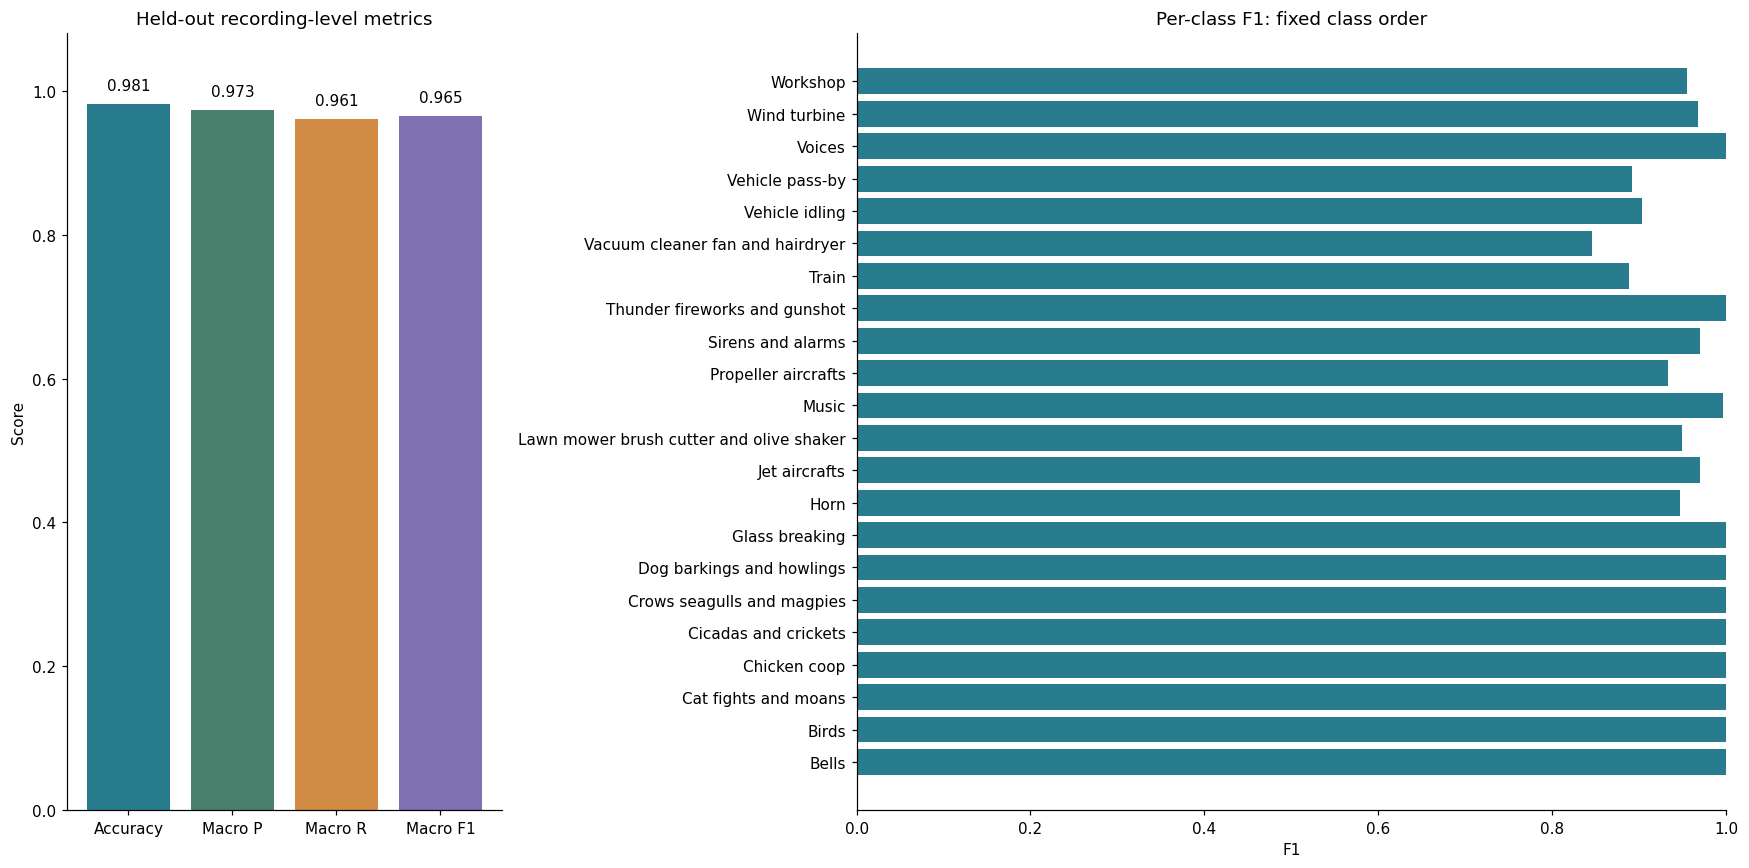

,precision,recall,f1-score,support
Bells,1.000000,1.000000,1.000000,10.0
Birds,1.000000,1.000000,1.000000,10.0
Cat fights and moans,1.000000,1.000000,1.000000,7.0
Chicken coop,1.000000,1.000000,1.000000,9.0
Cicadas and crickets,1.000000,1.000000,1.000000,11.0
Crows seagulls and magpies,1.000000,1.000000,1.000000,16.0
Dog barkings and howlings,1.000000,1.000000,1.000000,11.0
Glass breaking,1.000000,1.000000,1.000000,16.0
Horn,0.900000,1.000000,0.947368,9.0
Jet aircrafts,0.941176,1.000000,0.969697,16.0


In [25]:
if metrics is not None:
    keys = ["accuracy", "macro_precision", "macro_recall", "macro_f1"]
    display(
        pd.DataFrame(
            {"metric": keys, "score_percent": [100 * metrics[k] for k in keys]}
        ).round(2)
    )
    report_df = pd.read_csv(
        TEST_DIR / "classification_report.csv", index_col=0
    ).reindex(class_names)
    fig, axes = plt.subplots(
        1, 2, figsize=(16, 8), gridspec_kw={"width_ratios": [1, 2]}
    )
    bars = axes[0].bar(
        ["Accuracy", "Macro P", "Macro R", "Macro F1"],
        [metrics[k] for k in keys],
        color=["#287c8e", "#487f6d", "#d28c45", "#8071b2"],
    )
    axes[0].set(
        ylim=(0, 1.08), title="Held-out recording-level metrics", ylabel="Score"
    )
    for bar, k in zip(bars, keys):
        axes[0].text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.02,
            f"{metrics[k]:.3f}",
            ha="center",
        )
    axes[1].barh(class_names, report_df["f1-score"], color="#287c8e")
    axes[1].set(xlim=(0, 1), title="Per-class F1: fixed class order", xlabel="F1")
    fig.tight_layout()
    fig.savefig(FIGURES / "test_scorecard.png", bbox_inches="tight")
    plt.show()
    display(report_df[["precision", "recall", "f1-score", "support"]])
else:
    print("Test scorecard pending real evaluation.")


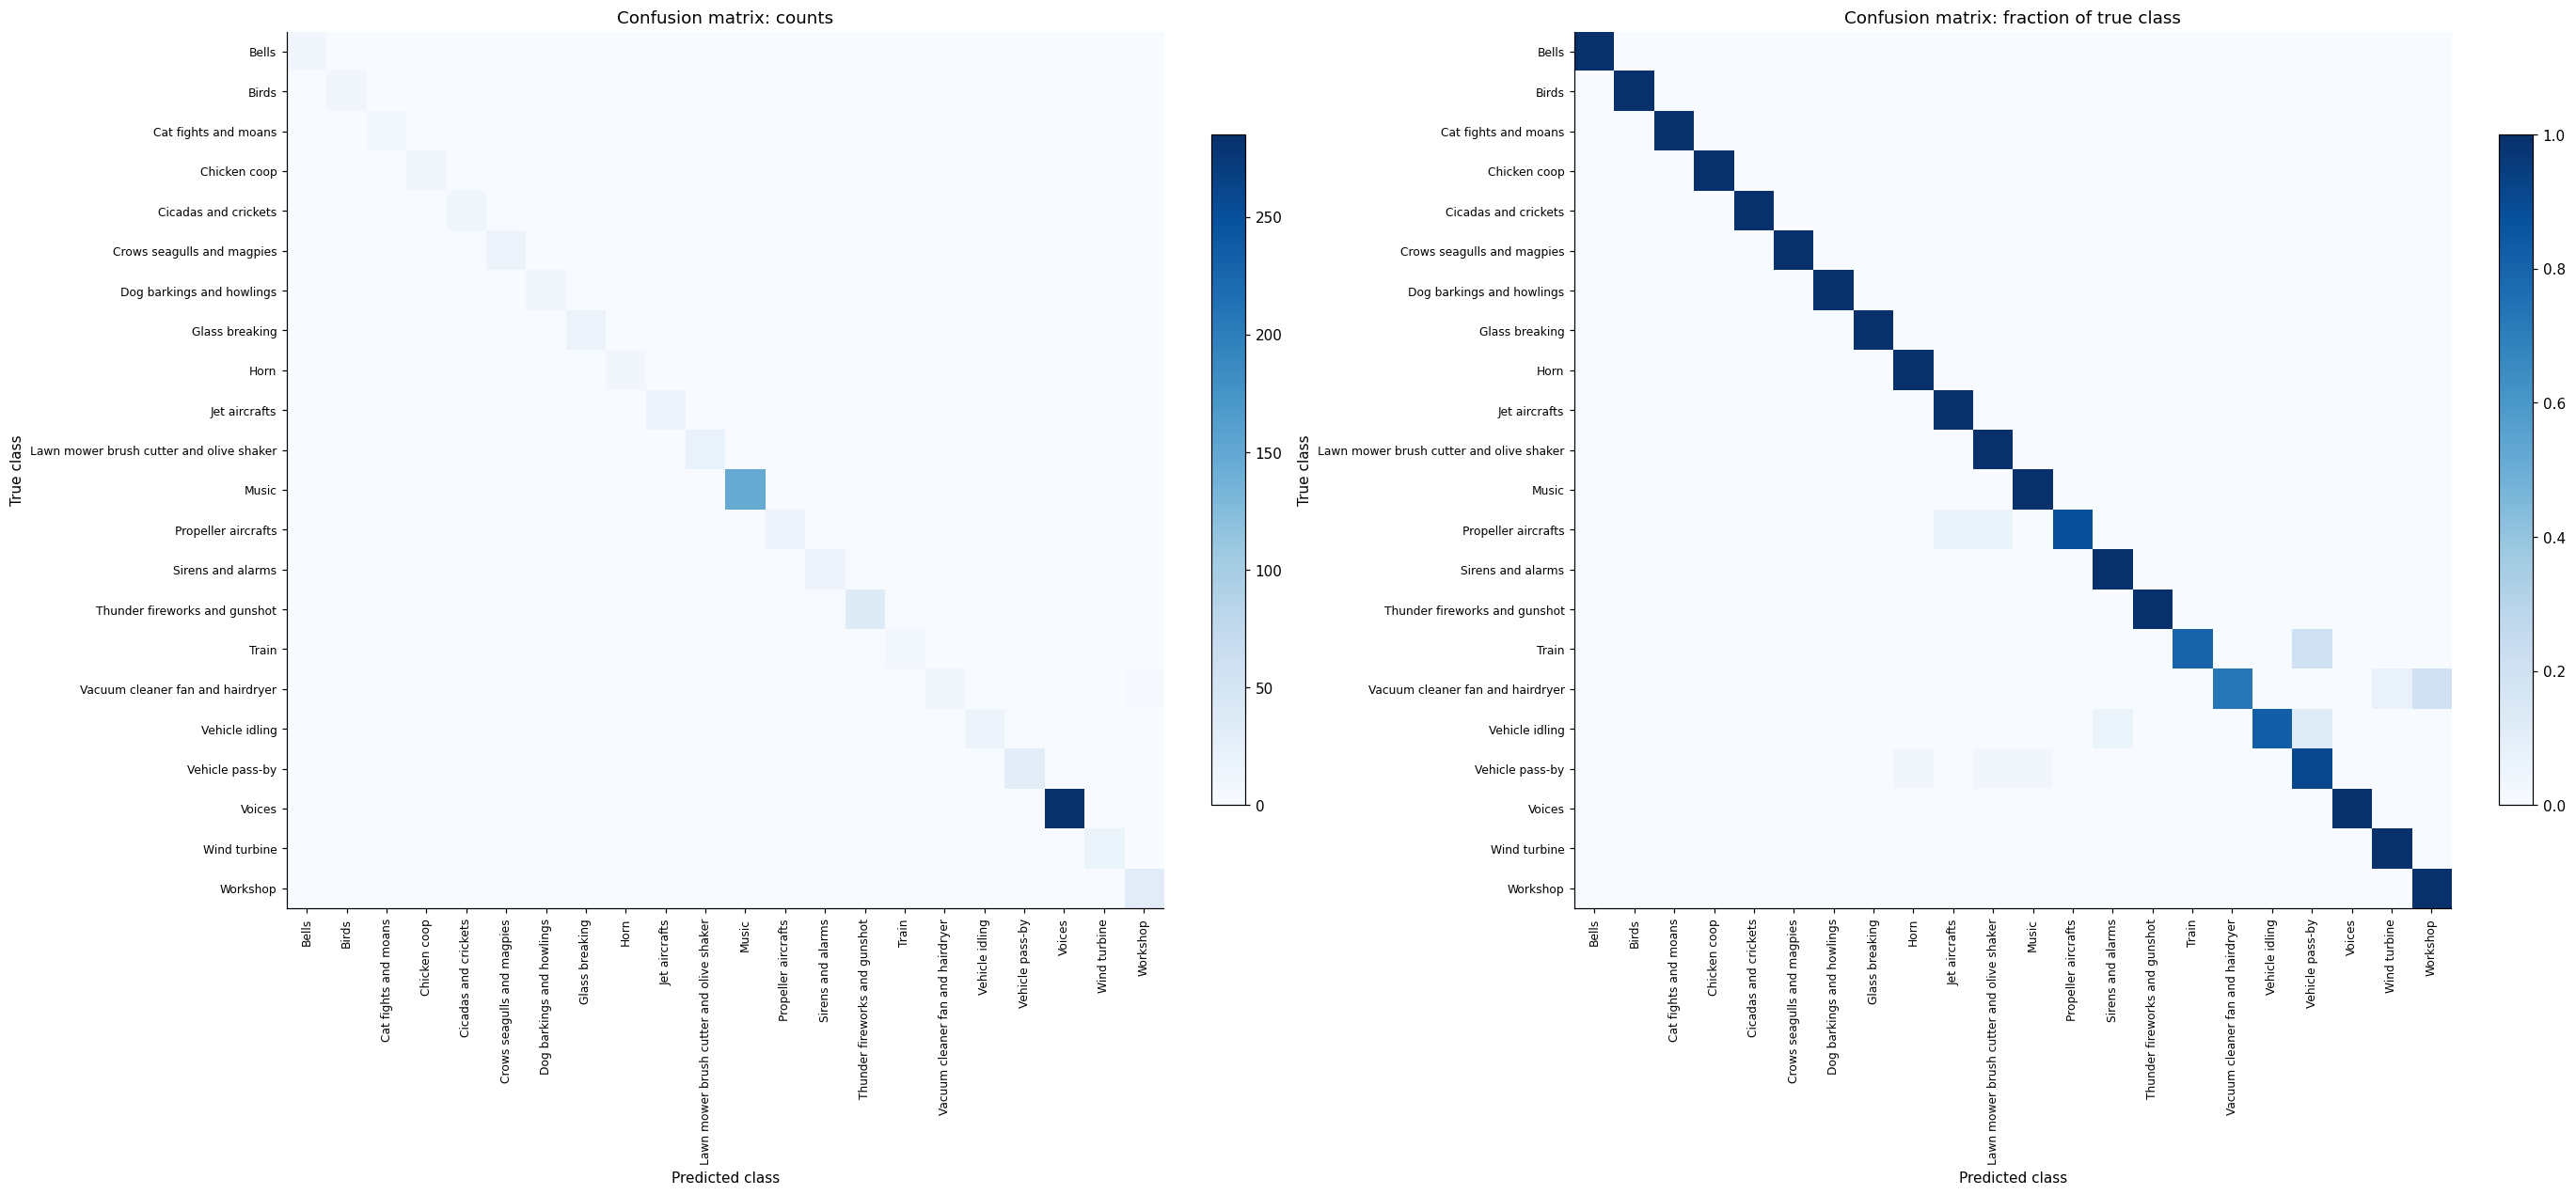

In [26]:
if metrics is not None:
    matrix = (
        pd.read_csv(TEST_DIR / "confusion_matrix.csv", index_col=0)
        .reindex(index=class_names, columns=class_names)
        .to_numpy()
    )
    normalized = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1)
    fig, axes = plt.subplots(1, 2, figsize=(25, 12))
    for ax, values, title in zip(
        axes,
        [matrix, normalized],
        ["Confusion matrix: counts", "Confusion matrix: fraction of true class"],
    ):
        im = ax.imshow(
            values,
            cmap="Blues",
            vmin=0,
            **({"vmax": 1} if values is normalized else {})
        )
        ax.set(
            xticks=range(22),
            yticks=range(22),
            xticklabels=class_names,
            yticklabels=class_names,
            xlabel="Predicted class",
            ylabel="True class",
            title=title,
        )
        plt.setp(ax.get_xticklabels(), rotation=90, fontsize=8)
        plt.setp(ax.get_yticklabels(), fontsize=8)
        fig.colorbar(im, ax=ax, fraction=0.035)
    fig.tight_layout()
    fig.savefig(FIGURES / "confusion_matrices.png", bbox_inches="tight")
    plt.show()
else:
    print("Confusion matrices pending real evaluation.")


## 13. Error analysis and WAV prediction

Frequent confusion pairs and high-score mistakes support qualitative analysis. Softmax scores are uncalibrated; listen before attributing errors to noise or overlapping events. Do not use these held-out mistakes to tune the reported experiment.

The demonstration uses the same resampling, feature extraction and crop averaging as evaluation. It shows a test recording's three highest class scores after evaluation. This classifier always selects among the 22 trained classes; it does not detect unknown events or provide streaming detection. The player previews up to 15 seconds, while inference uses the configured crop policy.

Incorrect recordings: 14 of 755


,label,predicted_class,count
0,Vacuum cleaner fan and hairdryer,Workshop,3
1,Train,Vehicle pass-by,2
2,Vehicle idling,Vehicle pass-by,2
3,Propeller aircrafts,Jet aircrafts,1
4,Propeller aircrafts,Lawn mower brush cutter and olive shaker,1
5,Vacuum cleaner fan and hairdryer,Wind turbine,1
6,Vehicle idling,Sirens and alarms,1
7,Vehicle pass-by,Horn,1
8,Vehicle pass-by,Lawn mower brush cutter and olive shaker,1
9,Vehicle pass-by,Music,1


,relative_path,label,predicted_class,score
353,Train/Train-0017.wav,Train,Vehicle pass-by,0.998471
367,Vacuum cleaner fan and hairdryer/vacuum cleane...,Vacuum cleaner fan and hairdryer,Workshop,0.960669
397,Vehicle pass-by/car pass-by/car pass-by-0017.wav,Vehicle pass-by,Horn,0.937308
368,Vacuum cleaner fan and hairdryer/vacuum cleane...,Vacuum cleaner fan and hairdryer,Workshop,0.875178
385,Vehicle idling/motorbike idling/motorbike idli...,Vehicle idling,Vehicle pass-by,0.868195
283,Propeller aircrafts/Airplanes/Airplanes-0007.wav,Propeller aircrafts,Jet aircrafts,0.830327
410,Vehicle pass-by/motorbike pass-by/motorbike pa...,Vehicle pass-by,Lawn mower brush cutter and olive shaker,0.803084
373,Vacuum cleaner fan and hairdryer/vacuum cleane...,Vacuum cleaner fan and hairdryer,Workshop,0.679853
376,Vehicle idling/car truck idling/car truck idli...,Vehicle idling,Vehicle pass-by,0.579269
291,Propeller aircrafts/Helicopters/Helicopters-00...,Propeller aircrafts,Lawn mower brush cutter and olive shaker,0.574778


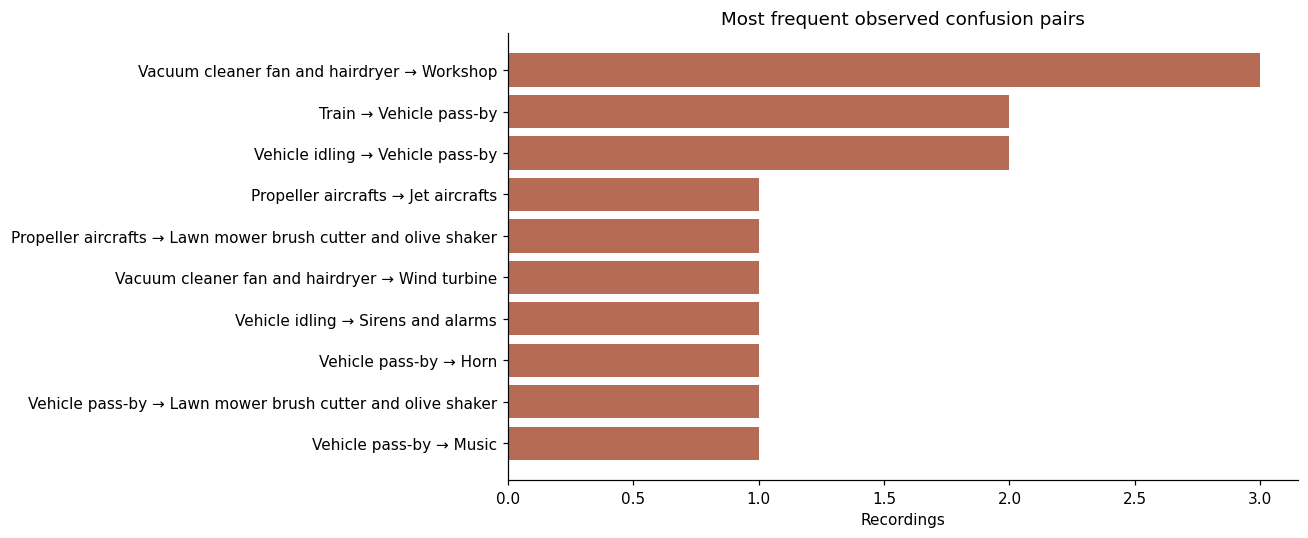

In [27]:
if metrics is not None:
    predictions = pd.read_csv(TEST_DIR / "predictions.csv")
    assert (
        predictions.relative_path.tolist() == partitions["test"].relative_path.tolist()
    ), "Prediction identities differ."
    predictions["predicted_class"] = predictions.prediction.map(
        dict(enumerate(class_names))
    )
    mistakes = predictions[predictions.target != predictions.prediction].copy()
    print("Incorrect recordings:", len(mistakes), "of", len(predictions))
    pairs = (
        mistakes.groupby(["label", "predicted_class"])
        .size()
        .sort_values(ascending=False)
        .head(10)
        .rename("count")
        .reset_index()
    )
    display(pairs)
    display(
        mistakes.sort_values("score", ascending=False)[
            ["relative_path", "label", "predicted_class", "score"]
        ].head(10)
    )
    if len(pairs):
        fig, ax = plt.subplots(figsize=(12, 5))
        ax.barh(
            pairs.label + " → " + pairs.predicted_class, pairs["count"], color="#b66b54"
        )
        ax.invert_yaxis()
        ax.set(title="Most frequent observed confusion pairs", xlabel="Recordings")
        fig.tight_layout()
        fig.savefig(FIGURES / "confusion_pairs.png", bbox_inches="tight")
        plt.show()
else:
    print("Error analysis pending real predictions.")


True label: Bells | Predicted: Bells


,class_id,label,score
0,0,Bells,0.999354
1,21,Workshop,0.000082
2,14,Thunder fireworks and gunshot,0.000071


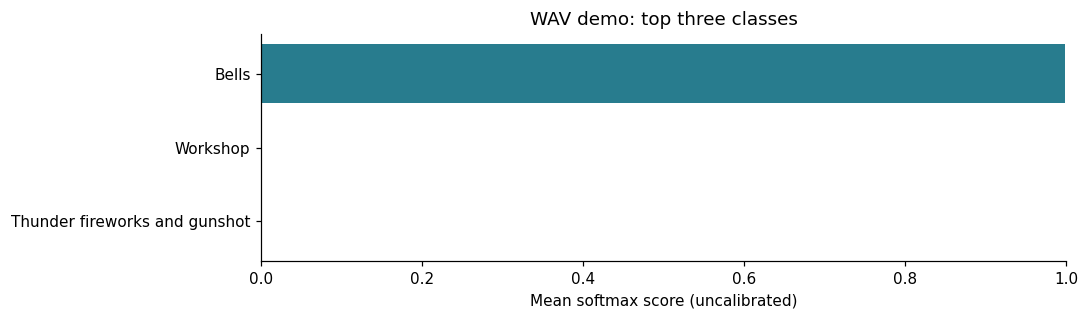

Player previews up to 15 seconds; inference uses the configured crop policy.


In [28]:
if metrics is not None and RUN_PREDICTION_DEMO:
    if best_model is None:
        best_model, extractor, state = load_best(RUN, DEVICE)
    assert (
        not state["smoke"]
        and state["mapping"] == mapping
        and state["fingerprint"] == fingerprint(frame)
    )
    demo_row = partitions["test"].iloc[0]
    prediction = predict_wav(
        DATA_DIR / demo_row.relative_path,
        best_model,
        extractor,
        mapping,
        DEVICE,
        CFG["eval_crops"],
    )
    (FIGURES / "prediction_demo.json").write_text(json.dumps(prediction, indent=2))
    print("True label:", demo_row.label, "| Predicted:", prediction["label"])
    top = pd.DataFrame(prediction["top_three"])
    display(top)
    fig, ax = plt.subplots(figsize=(10, 3))
    ax.barh(top.label, top.score, color="#287c8e")
    ax.invert_yaxis()
    ax.set(
        xlim=(0, 1),
        xlabel="Mean softmax score (uncalibrated)",
        title="WAV demo: top three classes",
    )
    fig.tight_layout()
    fig.savefig(FIGURES / "prediction_top_three.png", bbox_inches="tight")
    plt.show()
    wave = load_audio(DATA_DIR / demo_row.relative_path, extractor.sampling_rate)
    display(Audio(wave[: 15 * extractor.sampling_rate], rate=extractor.sampling_rate))
    print(
        "Player previews up to 15 seconds; inference uses the configured crop policy."
    )
else:
    print("Demo not run: test results pending, or disabled in configuration.")


## 14. Results, saved artifacts and limitations

The summary records measured metrics, hardware, crop policy, selected epoch and training time. Keep the model checkpoint, processor, model configuration, class mapping, split manifest, history and evaluation reports together. They are written under `/kaggle/working/ast_datasec`; retain the Kaggle version outputs for experiments you want to keep.

A fair architecture comparison requires the same dataset release, labels and recording partitions, with pretraining and evaluation policies disclosed. Limitations include possible source overlap without metadata, exact hashes missing near-duplicates, frequencies above 8 kHz being removed by 16 kHz resampling, sampled coverage of long recordings and variability across random seeds. One run does not establish statistical superiority.

In [29]:
if metrics is not None:
    comparison = {
        **metrics,
        "completed_epochs": len(history_df),
        "training_validation_seconds": float(history_df.seconds.sum()),
    }
    pd.DataFrame([comparison]).to_csv(FIGURES / "comparison_row.csv", index=False)
    display(pd.Series(comparison, name="Measured AST experiment").to_frame())
checks = {
    name: (RUN / name).exists()
    for name in [
        "best.pt",
        "last.pt",
        "history.csv",
        "config.json",
        "split_manifest.csv",
        "class_mapping.json",
        "test/metrics.json",
        "test/predictions.csv",
    ]
}
display(pd.Series(checks, name="Artifact exists").to_frame())
print("Presentation figures:", FIGURES)
print("Experiment and checkpoints:", RUN)
print(
    "Keep the complete run folder. Existing checkpoints and test results were not overwritten."
)


,Measured AST experiment
accuracy,0.981457
macro_precision,0.973226
macro_recall,0.960823
macro_f1,0.964558
loss,0.067101
recordings,755
forward_ms_per_recording,120.754622
end_to_end_ms_per_recording,171.250844
model,AST
selected_epoch,8


,Artifact exists
best.pt,True
last.pt,True
history.csv,True
config.json,True
split_manifest.csv,True
class_mapping.json,True
test/metrics.json,True
test/predictions.csv,True


Presentation figures: /kaggle/working/ast_datasec/run_20261029_160714_238935_presentation
Experiment and checkpoints: /kaggle/working/ast_datasec/run_20261029_160714_238935
Keep the complete run folder. Existing checkpoints and test results were not overwritten.


### Validation status

All code cells were syntax-checked. A local test used 220 synthetic WAVs across all 22 classes and a small genuine AST to exercise the complete notebook workflow, including smoke training, full training, validation, checkpoint reload, test evaluation, plots and prediction. A second Run All started a fresh experiment and preserved earlier results. Download-checksum retry, unsafe ZIP rejection and interrupted evaluation saving were also tested.

These checks do not establish real DataSEC accuracy or full-size AST GPU memory and runtime requirements. The actual DataSEC experiment must run on Kaggle.

## References

1. Gong, Y., Chung, Y.-A. and Glass, J. (2021). [AST: Audio Spectrogram Transformer](https://arxiv.org/abs/2104.01778).
2. [MIT AudioSet-pretrained AST checkpoint](https://huggingface.co/MIT/ast-finetuned-audioset-10-10-0.4593), revision `f826b80d28226b62986cc218e5cec390b1096902`.
3. [Transformers AST implementation, version 4.57.1](https://github.com/huggingface/transformers/tree/v4.57.1/src/transformers/models/audio_spectrogram_transformer).
4. [DataSEC dataset release](https://zenodo.org/records/17033970). Archive integrity is checked against MD5 `29fa9b8cc84cfa69aa4e5e674e780383`.
5. Parent-label taxonomy and decoded-audio hash convention adapted from the supplied SincNet notebook.

ChatGPT Codex assisted with code inspection, implementation, formatting and synthetic workflow testing. Describe and disclose the assistance according to your course requirements.